# Projeto Final — Expressão Gráfica Computacional (PUC-Campinas)
## Entrega 2 — Aquisição, leitura, validação e pré-processamento da SpO₂ nas três bases

**Tema:** Efeito da frequência de amostragem e do pré-processamento da SpO₂ na detecção de apneia do sono por índice de dessaturação (ODI).
**Artigo de referência:** Yam et al. (2026), *JMIR* 28:e80349, DOI 10.2196/80349.
**Dupla:** Lara Madaschi Heinrich Piaia (RA 24025386) e _(nome / RA)_

| Base | Papel no projeto | SpO₂ | Referência |
|---|---|---|---|
| UCDDB (PhysioNet) | principal | EDF, 25 noites | apneias e hipopneias com início e duração (1 técnica) |
| APNEA HRV+SpO₂ (Mendeley Data) | externa 1 — outro oxímetro e população | 50 Hz (documentação), 83 sujeitos | rótulo apneia / não apneia por minuto |
| PSG-IPA (PhysioNet) | externa 2 — incerteza da referência | EDF+, 4 Hz, 5 PSGs | eventos pontuados por 12 avaliadores |

| Item pedido | Onde está |
|---|---|
| Bases baixadas, com versão/DOI e data de acesso | Seção 1 → `saidas/registro_acesso.json` |
| Metadados de aquisição (fs, resolução, ganho, unidade) | Seção 7.1 → `saidas/metadados_aquisicao.csv` |
| Script que lê, converte para unidade física, valida e pré-processa | Seções 2, 3, 6 e 7 |
| Descrição das bases (registros, duração, fs) | Seção 7.2 → `saidas/descricao_bases.csv` |
| Figuras do sinal bruto e pré-processado | Seção 8 → `saidas/figuras/` |
| Dúvidas concretas sobre o algoritmo principal | Seção 9 |

Cada função segue o cabeçalho padronizado da Entrega 1 (objetivo, entradas, saídas, parâmetros).
Para rodar: **Ambiente de execução → Executar tudo** (CPU basta). São ~2 GB de download; com `USAR_DRIVE = True`
(padrão) os dados ficam na pasta `egc_apneia` do Google Drive e não são baixados de novo. No fim, a Seção 11 gera
`saidas_entrega2.zip` com as tabelas e figuras para colocar no repositório.

## 0. Configuração

In [1]:
!pip -q install pyedflib PyWavelets xlrd wfdb h5py

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, re, json, hashlib, math, shutil, zipfile, warnings, urllib.request, datetime as dt
from pathlib import Path
from fractions import Fraction
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, io as sio
from scipy.ndimage import uniform_filter1d

try:
    import pywt
except ImportError:
    pywt = None
    print("Aviso: PyWavelets não instalado — o pré-processamento por wavelet será pulado.")

BASES = {
    "ucddb": {
        "nome": "St. Vincent's University Hospital / University College Dublin Sleep Apnea Database (UCDDB)",
        "sigla": "UCDDB", "papel": "principal", "versao": "1.0.0", "doi": "10.13026/C26C7D",
        "url_arquivos": "https://physionet.org/files/ucddb/1.0.0/",
        "pagina": "https://physionet.org/content/ucddb/1.0.0/", "licenca": "ODC-By v1.0",
        "referencia": "apneias e hipopneias com início e duração, 1 técnica do sono"},
    "apnea_hrv_spo2": {
        "nome": "APNEA HRV+SpO2 Dataset (base HuGCDN2014-OXI, Hosp. Univ. Dr. Negrín)",
        "sigla": "APNEA HRV+SpO2", "papel": "externa 1", "versao": "1", "doi": "10.17632/cdxs63gdzc.1",
        "id_mendeley": "cdxs63gdzc", "pagina": "https://data.mendeley.com/datasets/cdxs63gdzc/1",
        "licenca": "CC BY 4.0", "fs_documentada": 50.0,
        "referencia": "rótulo apneia/não apneia por minuto, especialista (AASM)",
        "artigo": "Martín-González et al., Sensors 23(9):4267, 2023, DOI 10.3390/s23094267"},
    "psgipa": {
        "nome": "PSG-IPA: a PolySomnoGraphic Inter-scorer Performance Assessment database (tarefa respiratória)",
        "sigla": "PSG-IPA", "papel": "externa 2", "versao": "1.0.0", "doi": "10.13026/esx0-nw71",
        "url_arquivos": "https://physionet.org/files/psg-ipa/1.0.0/",
        "pagina": "https://physionet.org/content/psg-ipa/1.0.0/", "licenca": "CC BY 4.0",
        "referencia": "eventos respiratórios de 12 avaliadores (modo manual)"},
}

UCDDB_REGISTROS = [f"ucddb{n:03d}" for n in
                   [2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]]
PSGIPA_REGISTROS = [f"SN{i}" for i in range(1, 6)]
PSGIPA_AVALIADORES = list(range(1, 13))
PSGIPA_AVALIADOR_FIGURAS = 1   # avaliador usado como referência nas figuras e na checagem de alinhamento

USAR_DRIVE = True    # guarda os dados no Google Drive (pede autorização); use False para não usar o Drive
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/egc_apneia")
else:
    RAIZ = Path(".")

DADOS_DIR = RAIZ / "dados"          # arquivos originais, nunca editados
SAIDA_DIR = RAIZ / "saidas"
FIG_DIR = SAIDA_DIR / "figuras"
PRE_DIR = SAIDA_DIR / "preprocessado"
for p in [FIG_DIR, PRE_DIR] + [DADOS_DIR / b for b in BASES] + [PRE_DIR / b for b in BASES]:
    p.mkdir(parents=True, exist_ok=True)

# Parâmetros da Entrega 1 (fatores em teste)
FS_ALVO = ["nativa", 4.0, 1.0, 0.5, 0.2]           # Hz
PREPROC = ["nenhum", "media_movel", "wavelet"]
EPOCA_S = 30
ESTAGIOS_SONO = {1, 2, 3, 4, 5}      # código comum: 0 W, 1 REM, 2 N1/S1, 3 N2/S2, 4 N3/S3, 5 S4, 6 artefato, 7 indet., -1 sem estágio

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

Mounted at /content/drive


## 1. Aquisição: download, integridade e registro de acesso

* **UCDDB** e **PSG-IPA** vêm do PhysioNet; cada arquivo é conferido com o `SHA256SUMS.txt` publicado pela base.
  Só são baixados os arquivos usados: na UCDDB, `.rec` (PSG), `_respevt.txt` (eventos) e `_stage.txt`
  (hipnograma); na PSG-IPA, os 5 EDF da tarefa respiratória e as anotações manuais dos 12 avaliadores.
* **APNEA HRV+SpO₂** vem do Mendeley Data. O Mendeley costuma bloquear downloads automáticos (erro 403); nesse
  caso o notebook:
  1. procura um .zip da base que você já tenha colocado no Colab (pasta `dados/apnea_hrv_spo2/`, `/content` ou,
     com `USAR_DRIVE = True`, a raiz do Google Drive);
  2. se não achar, abre um botão **Escolher arquivos** para você enviar o .zip baixado pelo botão
     **Download All** da [página da base](https://data.mendeley.com/datasets/cdxs63gdzc/1).

  O Mendeley não publica hashes, então o notebook gera um manifesto SHA-256 dos arquivos recebidos para registrar
  exatamente o que foi usado. Se mesmo assim a base não for obtida, as outras duas seguem normalmente.

A data de acesso de cada base é gravada no primeiro download e mantida nas execuções seguintes.

In [3]:
def sha256_arquivo(caminho, bloco=2 ** 20):
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for parte in iter(lambda: f.read(bloco), b""):
            h.update(parte)
    return h.hexdigest()


def baixar_arquivos(url_base, relativos, destino):
    '''
    Objetivo : baixar arquivos de um repositório mantendo o caminho relativo original, sem edição.
    Entradas : url_base (str), relativos (lista de caminhos relativos), destino (Path).
    Saídas   : lista de (Path local, caminho relativo).
    Parâmetros: arquivos já presentes não são baixados de novo; o download vai para .part e só é renomeado no fim.
    '''
    saida = []
    for i, rel in enumerate(relativos, 1):
        alvo = destino / rel
        alvo.parent.mkdir(parents=True, exist_ok=True)
        if not (alvo.exists() and alvo.stat().st_size > 0):
            print(f"  [{i}/{len(relativos)}] {rel}")
            tmp = alvo.with_name(alvo.name + ".part")
            urllib.request.urlretrieve(url_base + rel, tmp)
            tmp.rename(alvo)
        saida.append((alvo, rel))
    return saida


def verificar_sha256(arquivos, arquivo_somas=None):
    '''
    Objetivo : conferir cada arquivo com o hash publicado (ou só registrar o hash, se a base não publica).
    Entradas : arquivos (lista de (Path, rel)), arquivo_somas (Path do SHA256SUMS.txt ou None).
    Saídas   : DataFrame com arquivo, bytes, sha256 calculado e situação.
    '''
    esperado = {}
    if arquivo_somas is not None and arquivo_somas.exists():
        for linha in arquivo_somas.read_text().splitlines():
            partes = linha.split()
            if len(partes) == 2:
                esperado[partes[1].lstrip("./")] = partes[0].lower()
    linhas = []
    for caminho, rel in arquivos:
        if arquivo_somas is not None and caminho.name == arquivo_somas.name:
            continue
        h = sha256_arquivo(caminho)
        if arquivo_somas is None:
            situacao = "sem hash publicado"
        elif rel not in esperado:
            situacao = "sem hash na lista"
        else:
            situacao = "ok" if esperado[rel] == h else "DIVERGENTE"
        linhas.append({"arquivo": rel, "bytes": caminho.stat().st_size, "sha256": h, "situacao": situacao})
    return pd.DataFrame(linhas)


CABECALHOS = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
                            "Chrome/124.0 Safari/537.36", "Accept": "*/*"}


def baixar_url(url, alvo):
    '''Baixa `url` para `alvo` com cabeçalho de navegador (o Mendeley recusa o cliente padrão do Python).'''
    tmp = alvo.with_name(alvo.name + ".part")
    with urllib.request.urlopen(urllib.request.Request(url, headers=CABECALHOS), timeout=120) as r, open(tmp, "wb") as f:
        while parte := r.read(2 ** 20):
            f.write(parte)
    tmp.rename(alvo)


def eh_zip_mendeley(p):
    return p.suffix.lower() == ".zip" and re.search(r"cdxs63gdzc|apnea|hrv|spo2", p.name, re.I) is not None


def baixar_mendeley(id_dataset, versao, destino):
    '''
    Objetivo : obter o pacote completo de um dataset do Mendeley Data e extraí-lo.
    Entradas : id_dataset (str), versao (str), destino (Path).
    Saídas   : lista de (Path, rel) dos arquivos extraídos (sem os .zip).
    Parâmetros: ordem de tentativa — (1) .zip já presente no Colab/Drive; (2) pacote "Download All";
                (3) API pública; (4) envio manual do .zip pelo botão "Escolher arquivos" do Colab.
    '''
    tem_dados = any(p.is_file() and p.suffix != ".extraido" for p in destino.rglob("*"))
    if not tem_dados:
        # (1) zip colocado à mão em algum lugar comum
        lugares = [RAIZ, Path("/content"), Path("/content/drive/MyDrive")]
        achados = [p for l in lugares if l.exists() for p in l.glob("*.zip") if eh_zip_mendeley(p)]
        if achados:
            print(f"  usando {achados[0]}")
            shutil.copy2(achados[0], destino / achados[0].name)
            tem_dados = True
    if not tem_dados:
        # (2) e (3) download automático
        try:
            print("  baixando pacote completo do Mendeley Data ...")
            baixar_url(f"https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/{id_dataset}-{versao}.zip",
                       destino / f"{id_dataset}-{versao}.zip")
            tem_dados = True
        except Exception as e:
            print("  pacote completo indisponível:", type(e).__name__, e)
    if not tem_dados:
        try:
            api = f"https://data.mendeley.com/public-api/datasets/{id_dataset}/files?folder_id=root&version={versao}"
            with urllib.request.urlopen(urllib.request.Request(api, headers=CABECALHOS), timeout=60) as r:
                itens = json.load(r)
            for it in itens:
                print("  baixando", it["filename"])
                baixar_url(it["content_details"]["download_url"], destino / it["filename"])
            tem_dados = len(itens) > 0
        except Exception as e:
            print("  API do Mendeley indisponível:", type(e).__name__, e)
    if not tem_dados:
        # (4) envio manual pelo Colab
        try:
            from google.colab import files
        except ImportError:
            files = None
        if files is None:
            raise RuntimeError(f"Baixe o .zip pelo botão 'Download All' em {BASES['apnea_hrv_spo2']['pagina']} "
                               f"e coloque-o em {destino.resolve()}; depois rode esta célula de novo.")
        print(f"\n  >>> O Mendeley bloqueou o download automático.\n"
              f"  >>> 1. Abra {BASES['apnea_hrv_spo2']['pagina']} e clique em 'Download All'.\n"
              f"  >>> 2. Clique em 'Escolher arquivos' abaixo e selecione o .zip baixado.\n")
        enviados = files.upload()
        for nome, conteudo in enviados.items():
            (destino / nome).write_bytes(conteudo)
        Path(next(iter(enviados), "x")).unlink(missing_ok=True)   # files.upload também grava em /content
        tem_dados = bool(enviados)
        if not tem_dados:
            raise RuntimeError("Nenhum arquivo enviado.")
    # extrai todos os .zip (inclusive .zip dentro de .zip)
    while True:
        pendentes = [z for z in destino.rglob("*.zip") if not (z.parent / (z.stem + ".extraido")).exists()]
        if not pendentes:
            break
        for z in pendentes:
            print("  extraindo", z.name)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z.parent / z.stem)
            (z.parent / (z.stem + ".extraido")).write_text("ok")
    return [(p, str(p.relative_to(destino))) for p in sorted(destino.rglob("*"))
            if p.is_file() and p.suffix.lower() not in (".zip", ".extraido", ".part")]


arquivos_base, integridade = {}, {}

# UCDDB
print("UCDDB")
d = DADOS_DIR / "ucddb"
rels = ["SHA256SUMS.txt", "RECORDS", "SubjectDetails.xls"] + \
       [f"{r}{s}" for r in UCDDB_REGISTROS for s in (".rec", "_respevt.txt", "_stage.txt")]
arquivos_base["ucddb"] = baixar_arquivos(BASES["ucddb"]["url_arquivos"], rels, d)
integridade["ucddb"] = verificar_sha256(arquivos_base["ucddb"], d / "SHA256SUMS.txt")

# PSG-IPA (tarefa respiratória)
print("PSG-IPA")
d = DADOS_DIR / "psgipa"
rels = ["SHA256SUMS.txt"] + [f"Resp_events/PSG/{sn}_Respiration.edf" for sn in PSGIPA_REGISTROS] + \
       [f"Resp_events/Annotations/manual/{sn}_Respiration_manual_scorer{k}.txt"
        for sn in PSGIPA_REGISTROS for k in PSGIPA_AVALIADORES]
arquivos_base["psgipa"] = baixar_arquivos(BASES["psgipa"]["url_arquivos"], rels, d)
integridade["psgipa"] = verificar_sha256(arquivos_base["psgipa"], d / "SHA256SUMS.txt")

# APNEA HRV+SpO2 (Mendeley Data)
print("APNEA HRV+SpO2")
d = DADOS_DIR / "apnea_hrv_spo2"
try:
    arquivos_base["apnea_hrv_spo2"] = baixar_mendeley(BASES["apnea_hrv_spo2"]["id_mendeley"],
                                                      BASES["apnea_hrv_spo2"]["versao"], d)
    integridade["apnea_hrv_spo2"] = verificar_sha256(arquivos_base["apnea_hrv_spo2"], None)
    integridade["apnea_hrv_spo2"].to_csv(SAIDA_DIR / "manifesto_sha256_apnea_hrv_spo2.csv", index=False)
except Exception as e:
    print(f"\n  APNEA HRV+SpO2 NÃO obtida ({type(e).__name__}: {e}).\n"
          "  As outras bases seguem; rode esta célula de novo depois de colocar o .zip.")

for b, df in integridade.items():
    print(f"{BASES[b]['sigla']:>15}: {len(df)} arquivos, {df.bytes.sum() / 1e6:.0f} MB —",
          df["situacao"].value_counts().to_dict())
    assert (df["situacao"] != "DIVERGENTE").all(), f"{b}: arquivo corrompido; apague-o e rode de novo."

# Registro de acesso (data do primeiro download preservada por base)
reg_path = SAIDA_DIR / "registro_acesso.json"
agora = dt.datetime.now(ZoneInfo("America/Sao_Paulo")).isoformat(timespec="seconds")
registro = json.loads(reg_path.read_text()) if reg_path.exists() else {}
for b, df in integridade.items():
    r = registro.get(b, {**BASES[b], "data_acesso": agora})
    r.update({"ultima_execucao": agora, "n_arquivos": int(len(df)), "bytes_total": int(df["bytes"].sum()),
              "integridade": df["situacao"].value_counts().to_dict()})
    registro[b] = r
reg_path.write_text(json.dumps(registro, indent=2, ensure_ascii=False))
pd.DataFrame(registro).T[["sigla", "papel", "versao", "doi", "licenca", "data_acesso", "n_arquivos", "bytes_total"]]

UCDDB
PSG-IPA
APNEA HRV+SpO2
          UCDDB: 77 arquivos, 806 MB — {'ok': 77}
        PSG-IPA: 65 arquivos, 607 MB — {'ok': 65}
 APNEA HRV+SpO2: 249 arquivos, 108 MB — {'sem hash publicado': 249}


,sigla,papel,versao,doi,licenca,data_acesso,n_arquivos,bytes_total
ucddb,UCDDB,principal,1.0.0,10.13026/C26C7D,ODC-By v1.0,2026-11-11T18:59:48-03:00,77,806208734
psgipa,PSG-IPA,externa 2,1.0.0,10.13026/esx0-nw71,CC BY 4.0,2026-11-11T18:59:48-03:00,65,606971265
apnea_hrv_spo2,APNEA HRV+SpO2,externa 1,1,10.17632/cdxs63gdzc.1,CC BY 4.0,2026-11-11T18:59:48-03:00,249,107814825


## 2. Leitura dos dados brutos e conversão para unidade física

UCDDB (`.rec`) e PSG-IPA (`.edf`, EDF+) usam o formato **EDF**: cada canal é gravado como inteiro de 16 bits
(complemento de 2, *little-endian*) e o cabeçalho traz, por canal, a faixa digital `[d_min, d_max]` e a faixa
física `[p_min, p_max]`. A conversão é linear:

$$x_{\text{físico}} = p_{\min} + (x_{\text{digital}} - d_{\min})\cdot G, \qquad G = \frac{p_{\max}-p_{\min}}{d_{\max}-d_{\min}}$$

em que **G** é o ganho (unidade física por nível digital). O leitor abaixo faz essa conta a partir do cabeçalho
e, quando o pyEDFlib está disponível, confere o resultado com ele.

A APNEA HRV+SpO₂ não é EDF e o Mendeley não descreve o formato dos arquivos. O leitor dela (Seção 2.2) primeiro
inventaria o pacote e depois reconhece `.mat`, `.csv`/`.txt`, `.npy`, EDF e WFDB, localizando o sinal de SpO₂ e
os rótulos por minuto pelo nome das variáveis/arquivos.

In [4]:
CAMPOS_CANAL = [("rotulo", 16), ("transdutor", 80), ("unidade", 8), ("fis_min", 8), ("fis_max", 8),
                ("dig_min", 8), ("dig_max", 8), ("pre_filtro", 80), ("amostras_por_bloco", 8), ("reservado", 32)]
PADRAO_SPO2 = r"spo2|sao2|sat|oxi"


def ler_cabecalho_edf(caminho):
    '''
    Objetivo : ler o cabeçalho EDF/EDF+ (geral e por canal) sem depender de biblioteca externa.
    Entradas : caminho (Path).
    Saídas   : dict com campos gerais e DataFrame `canais` (um canal por linha, com fs e ganho).
    '''
    with open(caminho, "rb") as f:
        geral = f.read(256).decode("latin-1")
        ns = int(geral[252:256])
        bloco = f.read(256 * ns).decode("latin-1")
    cab = {"versao": geral[0:8].strip(), "reservado": geral[192:236].strip(), "data_inicio": geral[168:176].strip(),
           "hora_inicio": geral[176:184].strip(), "bytes_cabecalho": int(geral[184:192]),
           "n_blocos": int(geral[236:244]), "duracao_bloco_s": float(geral[244:252]), "n_canais": ns}
    pos, cols = 0, {}
    for nome, tam in CAMPOS_CANAL:
        cols[nome] = [bloco[pos + i * tam: pos + (i + 1) * tam].strip() for i in range(ns)]
        pos += tam * ns
    canais = pd.DataFrame(cols).drop(columns="reservado")
    for c in ("fis_min", "fis_max"):
        canais[c] = canais[c].astype(float)
    for c in ("dig_min", "dig_max", "amostras_por_bloco"):
        canais[c] = canais[c].astype(int)
    canais["fs_hz"] = canais["amostras_por_bloco"] / cab["duracao_bloco_s"]
    canais["ganho"] = (canais["fis_max"] - canais["fis_min"]) / (canais["dig_max"] - canais["dig_min"])
    cab["canais"] = canais
    return cab


def ler_canal_edf(caminho, padrao=PADRAO_SPO2):
    '''
    Objetivo : extrair um canal do EDF e convertê-lo de valor digital para unidade física.
    Entradas : caminho (Path); padrao (regex sem diferenciar maiúsculas) para achar o canal pelo rótulo.
    Saídas   : dict com sinal digital (int16), sinal físico (float64), fs, metadados do canal e do arquivo.
    Parâmetros: canais de anotação do EDF+ são ignorados na busca; o número de blocos é recalculado pelo
                tamanho do arquivo quando o cabeçalho traz -1 ou um valor incoerente.
    '''
    cab = ler_cabecalho_edf(caminho)
    canais = cab["canais"]
    if cab["reservado"].startswith("EDF+D"):
        print(f"  aviso {caminho.name}: EDF+ descontínuo; os blocos são concatenados sem lacunas")
    candidatos = canais.index[canais["rotulo"].str.contains(padrao, case=False, regex=True)
                              & ~canais["rotulo"].str.contains("annotation", case=False)]
    if len(candidatos) == 0:
        raise ValueError(f"{caminho.name}: nenhum canal casa com '{padrao}'. Rótulos: {list(canais['rotulo'])}")
    i = int(candidatos[0])
    spb = canais["amostras_por_bloco"].to_numpy()
    tam_bloco = int(spb.sum())
    bruto = np.fromfile(caminho, dtype="<i2", offset=cab["bytes_cabecalho"])
    n_blocos = len(bruto) // tam_bloco
    if cab["n_blocos"] not in (-1, n_blocos):
        print(f"  aviso {caminho.name}: cabeçalho diz {cab['n_blocos']} blocos, arquivo tem {n_blocos}")
    blocos = bruto[: n_blocos * tam_bloco].reshape(n_blocos, tam_bloco)
    ini = int(spb[:i].sum())
    digital = blocos[:, ini: ini + spb[i]].reshape(-1)
    c = canais.loc[i]
    fisico = c["fis_min"] + (digital.astype(np.float64) - c["dig_min"]) * c["ganho"]
    return {"digital": digital, "fisico": fisico, "fs": float(c["fs_hz"]), "canal": c.to_dict(),
            "cabecalho": {k: v for k, v in cab.items() if k != "canais"}, "todos_canais": canais}


def conferir_pyedflib(caminho):
    '''Compara o leitor próprio com o pyEDFlib no canal de SpO₂; devolve a diferença máxima (unidade física).'''
    import pyedflib
    proprio = ler_canal_edf(caminho)
    with pyedflib.EdfReader(str(caminho)) as r:
        j = [k for k, l in enumerate(r.getSignalLabels())
             if re.search(PADRAO_SPO2, l, re.I) and "annotation" not in l.lower()][0]
        ref = r.readSignal(j)
    n = min(len(ref), len(proprio["fisico"]))
    return float(np.max(np.abs(ref[:n] - proprio["fisico"][:n])))


for b, caminho in [("ucddb", DADOS_DIR / "ucddb" / f"{UCDDB_REGISTROS[0]}.rec"),
                   ("psgipa", DADOS_DIR / "psgipa" / "Resp_events" / "PSG" / f"{PSGIPA_REGISTROS[0]}_Respiration.edf")]:
    try:
        print(f"{BASES[b]['sigla']}: diferença máxima leitor próprio × pyEDFlib = {conferir_pyedflib(caminho):.2e}")
    except Exception as e:
        print(f"{BASES[b]['sigla']}: conferência com pyEDFlib não realizada ({type(e).__name__}: {e})")
    cab = ler_cabecalho_edf(caminho)
    print(f"  canais de {caminho.name}:")
    print(cab["canais"][["rotulo", "unidade", "fs_hz", "dig_min", "dig_max", "fis_min", "fis_max", "ganho"]]
          .to_string(index=False), "\n")

UCDDB: diferença máxima leitor próprio × pyEDFlib = 0.00e+00
  canais de ucddb002.rec:
  rotulo unidade  fs_hz  dig_min  dig_max  fis_min  fis_max    ganho
 Lefteye      NV   64.0    -2048     2047      0.0      1.0 0.000244
RightEye      NV   64.0    -2048     2047      0.0      1.0 0.000244
     EMG      NV   64.0    -2048     2047      0.0      1.0 0.000244
    C3A2      NV  128.0    -2048     2047      0.0      1.0 0.000244
    C4A1      NV  128.0    -2048     2047      0.0      1.0 0.000244
     ECG      NV  128.0    -2048     2047      0.0      1.0 0.000244
    SpO2       %    8.0    -2048     2047      0.0     97.0 0.023687
   Sound            8.0    -2048     2047     -1.0      1.0 0.000488
    Flow   L/min    8.0    -2048     2047     -5.0      5.0 0.002442
     Sum            8.0    -2048     2047     -1.0      1.0 0.000488
 ribcage            8.0    -2048     2047     -1.0      1.0 0.000488
    abdo            8.0    -2048     2047     -1.0      1.0 0.000488
 BodyPos        

### 2.1 Anotações da UCDDB e da PSG-IPA

* **UCDDB** — `_respevt.txt`: cada evento com horário (hora do relógio), tipo (`APNEA-O/C/M`, `HYP-O/C/M`,
  `PB`/`CS`), duração (s) e, quando há, nadir e queda (%) da dessaturação; `_stage.txt`: um estágio por época de
  30 s (0 W, 1 REM, 2–5 estágios 1–4, 6 artefato, 7 indeterminado). Como os eventos estão em hora do relógio, o
  horário de início da PSG vem do `SubjectDetails.xls` (ou do cabeçalho EDF, se a planilha não abrir).
* **PSG-IPA** — um `.txt` por avaliador com início em segundos desde o começo do registro (*Recording onset*),
  duração e rótulo EDF+ (`Obstructive apnea`, `Central apnea`, `Mixed apnea`, `Hypopnea`, `Sleep stage W/N1/N2/N3/R`,
  `Lights off/on` ...). Os estágios vêm pré-preenchidos e iguais para todos os avaliadores; os eventos respiratórios
  variam de avaliador para avaliador.

Os estágios das duas bases são levados para o mesmo código (0 W, 1 REM, 2 N1, 3 N2, 4 N3, 5 S4).

In [5]:
def hora_para_segundos(valor):
    '''Converte hora (texto 'hh:mm:ss'/'hh.mm.ss', time, Timestamp ou fração de dia) em segundos do dia.'''
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return None
    if isinstance(valor, (dt.time, dt.datetime, pd.Timestamp)):
        return valor.hour * 3600 + valor.minute * 60 + valor.second
    if isinstance(valor, (int, float, np.floating)):
        return int(round(float(valor) % 1 * 86400))
    m = re.search(r"(\d{1,2})[:.](\d{2})[:.](\d{2})", str(valor))
    return int(m[1]) * 3600 + int(m[2]) * 60 + int(m[3]) if m else None


COLUNAS_EVENTOS = ["inicio_s", "duracao_s", "fim_s", "tipo", "classe", "spo2_nadir", "queda_pct"]


def ler_detalhes_ucddb(caminho):
    '''
    Objetivo : ler o SubjectDetails.xls e padronizar ID, horário de início da PSG e IAH.
    Saídas   : DataFrame indexado por registro ('ucddbNNN'), ou vazio se não for possível ler.
    '''
    try:
        df = pd.read_excel(caminho)
    except Exception as e:
        print("SubjectDetails.xls não lido:", type(e).__name__, e)
        return pd.DataFrame()
    df.columns = [str(c).strip() for c in df.columns]
    col_id = next((c for c in df.columns if re.search(r"study|subject|record|id", c, re.I)), df.columns[0])
    ids = df[col_id].astype(str).str.extract(r"(\d+)")[0]
    df.index = ["ucddb%03d" % int(v) if pd.notna(v) else None for v in ids]
    return df[df.index.notna()]


def ler_eventos_ucddb(caminho, inicio_s):
    '''
    Objetivo : ler o _respevt.txt e converter cada evento para segundos desde o início do registro.
    Entradas : caminho (Path), inicio_s (hora de início do registro, em segundos do dia).
    Saídas   : DataFrame com COLUNAS_EVENTOS (+ pb_cs).
    Parâmetros: eventos após a meia-noite são tratados pela aritmética módulo 24 h.
    '''
    linhas = []
    for linha in caminho.read_text(errors="replace").splitlines():
        tok = linha.split()
        if len(tok) < 3 or not re.fullmatch(r"\d{1,2}:\d{2}:\d{2}", tok[0]):
            continue
        tipo, k, pbcs = tok[1], 2, None
        if k < len(tok) and tok[k] in ("PB", "CS"):
            pbcs, k = tok[k], k + 1
        if k >= len(tok) or not re.fullmatch(r"\d+(\.\d+)?", tok[k]):
            continue
        dur = float(tok[k]); k += 1
        nums = []
        while k < len(tok) and tok[k] not in ("-", "+") and len(nums) < 2:
            try:
                nums.append(float(tok[k])); k += 1
            except ValueError:
                break
        t = (hora_para_segundos(tok[0]) - inicio_s) % 86400
        classe = "apneia" if tipo.startswith("APNEA") else "hipopneia" if tipo.startswith("HYP") else "resp_periodica"
        linhas.append({"inicio_s": t, "duracao_s": dur, "fim_s": t + dur, "tipo": tipo, "pb_cs": pbcs,
                       "classe": classe, "spo2_nadir": nums[0] if len(nums) == 2 else np.nan,
                       "queda_pct": nums[1] if len(nums) == 2 else np.nan})
    return pd.DataFrame(linhas, columns=COLUNAS_EVENTOS + ["pb_cs"])


def ler_estagios_ucddb(caminho):
    '''Lê o _stage.txt: um inteiro por época de 30 s (código R&K da base, já igual ao código comum).'''
    return np.array([int(v) for v in caminho.read_text().split() if v.strip().lstrip("-").isdigit()])


ESTAGIO_EDFPLUS = {"sleep stage w": 0, "sleep stage r": 1, "sleep stage n1": 2, "sleep stage n2": 3,
                   "sleep stage n3": 4, "sleep stage n4": 5, "sleep stage ?": 7}


def ler_anotacoes_psgipa(caminho):
    '''
    Objetivo : ler um arquivo de anotações da PSG-IPA (Date, Time, Recording onset, Duration, Annotation, ...).
    Saídas   : DataFrame com onset_s, duracao_s, rotulo.
    Parâmetros: separador detectado automaticamente; duração vazia vira 0.
    '''
    df = pd.read_csv(caminho, sep=None, engine="python", skipinitialspace=True)
    df.columns = [str(c).strip().lower() for c in df.columns]
    c_on = next(c for c in df.columns if "onset" in c)
    c_du = next(c for c in df.columns if "duration" in c)
    c_an = next(c for c in df.columns if "annotation" in c or "label" in c)
    return pd.DataFrame({"onset_s": pd.to_numeric(df[c_on], errors="coerce"),
                         "duracao_s": pd.to_numeric(df[c_du], errors="coerce").fillna(0.0),
                         "rotulo": df[c_an].astype(str).str.strip()}).dropna(subset=["onset_s"])


def estagios_psgipa(an, duracao_registro_s):
    '''Monta o hipnograma (uma época de 30 s por posição, código comum) a partir das anotações EDF+.'''
    est = np.full(int(np.ceil(duracao_registro_s / EPOCA_S)), -1)
    for _, a in an.iterrows():
        cod = ESTAGIO_EDFPLUS.get(a.rotulo.lower())
        if cod is None:
            continue
        i0 = int(round(a.onset_s / EPOCA_S))
        i1 = i0 + max(1, int(round((a.duracao_s or EPOCA_S) / EPOCA_S)))
        est[i0:min(i1, len(est))] = cod
    return est


def eventos_psgipa(an):
    '''Seleciona apneias e hipopneias das anotações EDF+ de um avaliador (formato de COLUNAS_EVENTOS).'''
    r = an["rotulo"].str.lower()
    sel = an[r.str.contains("apnea|hypopnea|apnoea|hypopnoea")].copy()
    sel["classe"] = np.where(sel["rotulo"].str.lower().str.contains("hypopn"), "hipopneia", "apneia")
    return pd.DataFrame({"inicio_s": sel.onset_s.to_numpy(), "duracao_s": sel.duracao_s.to_numpy(),
                         "fim_s": (sel.onset_s + sel.duracao_s).to_numpy(), "tipo": sel.rotulo.to_numpy(),
                         "classe": sel.classe.to_numpy(), "spo2_nadir": np.nan, "queda_pct": np.nan},
                        columns=COLUNAS_EVENTOS)

### 2.2 Leitor da APNEA HRV+SpO₂

O pacote do Mendeley (`HuGCDN2014-OXI/`) traz um `.mat` por sujeito em cada uma de três pastas:

| Pasta | Conteúdo | Uso |
|---|---|---|
| `SAT/` | SpO₂ da noite | sinal analisado |
| `LABELS/` | rótulo apneia / não apneia por minuto | referência |
| `RR/` | intervalos RR do ECG | não usado neste projeto |

O nome do arquivo identifica o sujeito e o grupo clínico: `C` = controle, `D` = dessaturante, `ND` = não
dessaturante (ex.: `SAT/D7.mat` e `LABELS/D7.mat` são o mesmo sujeito). Dentro de cada `.mat` o leitor percorre
todas as variáveis (inclusive *structs* e *cells*) e escolhe:

* **SpO₂** — na pasta `SAT` a SpO₂ vem em **janelas de 5 min deslocadas de 1 min, uma por minuto rotulado**
  (o rótulo vale para o minuto central; Martín-González et al., 2023). O sinal contínuo é reconstruído juntando o
  minuto central de cada janela, o que o deixa alinhado 1:1 com os rótulos; o leitor confere se janelas
  consecutivas de fato se sobrepõem em 4 min. Sem janelas, usa o vetor numérico mais longo;
* **rótulos** — a pasta `LABELS` traz `salida_man` (um rótulo a cada 30 s) e `salida_man_1m` (um por minuto);
  é usado o **rótulo por minuto**, alinhado ao minuto central de cada janela. Posições vazias de `SAT` (minutos nas
  bordas da noite, sem janela completa) viram lacuna, para manter o alinhamento;
* **fs** — uma única fs para a base: a variável `fs`/`freq`, se existir; senão os 50 Hz da documentação,
  **conferidos** pela mediana da razão amostras de SpO₂ ÷ minutos rotulados de todos os sujeitos. Sujeitos cuja
  razão destoa (sinal ou rótulos incompletos) são listados e ficam de fora das figuras.

Antes de processar, a célula mostra o conteúdo do primeiro arquivo de cada pasta (nomes, tipos, tamanhos e
valores), para que a escolha possa ser conferida.

In [6]:
PADRAO_ROTULO = r"label|annot|apn|target|class|rotulo"
SUFIXOS_SUJEITO = rf"({PADRAO_SPO2}|{PADRAO_ROTULO}|ecg|hrv|rri?|signal|sinal|data)\w*"
PAPEL_PASTA = [("spo2", r"^(sat|spo2|sao2|oxi\w*)$"), ("rotulos", r"^(labels?|annot\w*|rotulos?)$"),
               ("ignorar", r"^(rr|hrv|ecg|rri)$")]


def inventariar(pasta):
    '''Lista todos os arquivos de `pasta` (sem .zip e marcadores), com extensão e tamanho.'''
    linhas = [{"arquivo": str(p.relative_to(pasta)), "ext": p.suffix.lower(), "MB": p.stat().st_size / 1e6}
              for p in sorted(pasta.rglob("*"))
              if p.is_file() and p.suffix.lower() not in (".zip", ".extraido", ".part")]
    return pd.DataFrame(linhas, columns=["arquivo", "ext", "MB"])


def _achatar(obj, nome, saida):
    '''Percorre structs/cells do loadmat e guarda cada folha (array numérico ou texto) em `saida`.'''
    if hasattr(obj, "_fieldnames"):                       # struct (mat_struct)
        for f in obj._fieldnames:
            _achatar(getattr(obj, f), f"{nome}.{f}", saida)
    elif isinstance(obj, np.ndarray) and obj.dtype == object:
        if obj.size and all(isinstance(e, str) for e in obj.flat):      # cell de textos
            saida[nome] = np.array([str(e) for e in obj.flat])
        else:
            for j, e in enumerate(obj.flat):
                _achatar(e, f"{nome}[{j}]", saida)
    elif isinstance(obj, str):
        saida[nome] = np.array(list(obj)) if len(obj) > 1 else np.array([obj])
    elif isinstance(obj, np.ndarray) and obj.dtype.kind == "U":
        saida[nome] = np.array(list("".join(obj.ravel()))) if obj.size == 1 else obj.ravel()
    else:
        saida[nome] = np.asarray(obj)


def ler_mat(caminho):
    '''
    Objetivo : ler um .mat (v5 ou v7.3) e devolver todas as variáveis-folha como {nome: array}.
    Parâmetros: structs e cells são percorridos; textos viram vetor de caracteres.
    '''
    saida = {}
    try:
        d = sio.loadmat(caminho, squeeze_me=True, struct_as_record=False, chars_as_strings=True)
        for k, v in d.items():
            if not k.startswith("__"):
                _achatar(v, k, saida)
    except NotImplementedError:                            # MATLAB v7.3 = HDF5
        import h5py
        with h5py.File(caminho, "r") as f:
            def visitar(nome, obj):
                if isinstance(obj, h5py.Dataset) and not nome.startswith("#"):
                    a = np.array(obj).squeeze()
                    if obj.attrs.get("MATLAB_class", b"") in (b"char", "char"):
                        a = np.array(list("".join(map(chr, a.ravel()))))
                    saida[nome] = a
            f.visititems(visitar)
    return saida


def ler_variaveis(caminho):
    '''
    Objetivo : ler um arquivo de formato desconhecido e devolver suas variáveis como {nome: array}.
    Parâmetros: .mat (v5/v7.3), .csv/.txt/.tsv (com ou sem cabeçalho), .npy, .edf/.rec, .hea (WFDB).
    '''
    ext = caminho.suffix.lower()
    if ext == ".mat":
        return ler_mat(caminho)
    if ext in (".csv", ".txt", ".tsv"):
        amostra = [l for l in caminho.read_text(errors="replace").splitlines()[:50] if l.strip()]
        delim = next((d for d in [",", ";", "\t"] if amostra and all(d in l for l in amostra)), None)
        if delim is None and amostra and all(len(l.split()) > 1 for l in amostra):
            delim = r"\s+"
        df = pd.read_csv(caminho, sep=delim or ",", engine="python", header=None, skipinitialspace=True)
        col0 = df.iloc[:, 0].astype(str).str.strip()
        primeira_texto = pd.to_numeric(df.iloc[0], errors="coerce").isna().any()
        if primeira_texto and len(df) > 1 and col0.iloc[0] not in set(col0.iloc[1:]):   # 1ª linha é cabeçalho
            nomes = [str(c).strip() for c in df.iloc[0]]
            df.columns = [n if nomes.count(n) == 1 else f"{n}_{j}" for j, n in enumerate(nomes)]
            df = df.iloc[1:].reset_index(drop=True)
        else:
            df.columns = [f"{caminho.stem}_col{j}" if df.shape[1] > 1 else caminho.stem for j in range(df.shape[1])]
        out = {}
        for c in df.columns:
            num = pd.to_numeric(df[c], errors="coerce")
            out[c] = num.to_numpy() if num.notna().mean() > 0.95 else df[c].astype(str).str.strip().to_numpy()
        return out
    if ext == ".npy":
        return {caminho.stem: np.load(caminho, allow_pickle=False)}
    if ext in (".edf", ".rec"):
        lei = ler_canal_edf(caminho)
        return {"spo2__edf": lei["fisico"], "fs": np.array(lei["fs"])}
    if ext == ".hea":
        import wfdb
        rec = wfdb.rdrecord(str(caminho.with_suffix("")))
        out = {nome: rec.p_signal[:, j] for j, nome in enumerate(rec.sig_name)}
        out["fs"] = np.array(float(rec.fs))
        return out
    return {}


def descrever_variaveis(vars_, titulo):
    '''Mostra nome, tipo, forma e valores de cada variável (para conferir a leitura).'''
    print(f"  {titulo}")
    for k, v in vars_.items():
        v = np.asarray(v)
        info = f"    {k:<28} {str(v.dtype):<8} forma {str(v.shape):<14}"
        if v.dtype.kind in "iufb" and v.size:
            x = v.astype(float).ravel()
            info += f" mín {np.nanmin(x):.4g}  máx {np.nanmax(x):.4g}  mediana {np.nanmedian(x):.4g}"
        info += f"  início: {v.ravel()[:8].tolist()}"
        print(info[:220])


def papel_do_arquivo(p, pasta):
    '''Papel do arquivo pela pasta onde está ('spo2', 'rotulos', 'ignorar' ou None).'''
    for parte in reversed(p.relative_to(pasta).parts[:-1]):
        for papel, padrao in PAPEL_PASTA:
            if re.match(padrao, parte, re.I):
                return papel
    if re.search(PADRAO_SPO2, p.stem, re.I):
        return "spo2"
    if re.search(PADRAO_ROTULO, p.stem, re.I):
        return "rotulos"
    return None


def grupo_clinico(texto):
    '''Grupo clínico pelo prefixo do sujeito (C, D, ND) ou por palavras no caminho.'''
    nome = Path(texto).name
    if re.match(r"(?i)^nd\d", nome):
        return "não dessaturante"
    if re.match(r"(?i)^d\d", nome):
        return "dessaturante"
    if re.match(r"(?i)^c\d", nome):
        return "controle"
    t = texto.lower()
    if re.search(r"non[_\- ]?desat|no[_\- ]?desat|nondesat", t):
        return "não dessaturante"
    if re.search(r"desat", t):
        return "dessaturante"
    if re.search(r"control|normal|health|sano", t):
        return "controle"
    return None


def rotulos_para_bool(v):
    v = np.asarray(v).ravel()
    if v.dtype.kind in "iufb":
        return v.astype(float) > 0
    s = np.char.upper(np.char.strip(v.astype(str)))
    return np.isin(s, ["A", "APNEA", "APNOEA", "1", "Y", "YES", "S", "SIM", "TRUE"])


def montar_de_janelas(janelas, janela_min=5, passo_min=1):
    '''
    Objetivo : reconstruir a SpO₂ contínua a partir de janelas sobrepostas (uma por minuto rotulado).
    Entradas : janelas — lista de vetores, na ordem; cada um cobre `janela_min` minutos e começa
               `passo_min` minuto depois do anterior (APNEA HRV+SpO₂: 5 min, deslocamento de 1 min).
    Saídas   : (sinal, info) — sinal = minuto central de cada janela, concatenado (alinhado 1:1 com os
               rótulos, que valem para o minuto central); info = tamanho das janelas, fs implícita e
               fração de pares consecutivos cuja sobreposição confere com o deslocamento de 1 min.
    '''
    comps = np.array([len(w) for w in janelas])
    nominal = int(np.bincount(comps[comps > 0]).argmax())
    por_min = nominal // janela_min
    ini_centro = (janela_min - passo_min) // 2 * por_min
    partes, fora_padrao, vazias = [], 0, 0
    for w in janelas:
        if len(w) == 0:                                   # minuto sem janela (bordas da noite): lacuna
            vazias += 1
            partes.append(np.full(por_min, np.nan))
        elif len(w) == nominal:
            partes.append(w[ini_centro: ini_centro + por_min])
        else:
            fora_padrao += 1
            c = len(w) // 2
            seg = w[max(c - por_min // 2, 0): max(c - por_min // 2, 0) + por_min]
            partes.append(np.concatenate([seg, np.full(por_min - len(seg), np.nan)]))
    ok = tot = 0
    for a, b in zip(janelas[:-1], janelas[1:]):
        if len(a) == nominal and len(b) == nominal:
            tot += 1
            ok += bool(np.allclose(a[por_min:], b[:-por_min], equal_nan=True))
    info = {"n_janelas": len(janelas), "amostras_por_janela": nominal,
            "fs_janelas": nominal / (60 * janela_min), "janelas_fora_do_padrao": fora_padrao,
            "janelas_vazias": vazias,
            "sobreposicao_1min_confere": ok / tot if tot else np.nan}
    return np.concatenate(partes).astype(float), info


def escolher_spo2(vars_):
    '''
    Escolhe a SpO₂. Se houver várias janelas sob a mesma variável (cell array ou matriz janelas × amostras),
    reconstrói o sinal contínuo com montar_de_janelas; senão, o vetor numérico ≥ 3000 amostras
    (prefere nome com sat/spo2, senão o mais longo). Saídas: (nome, sinal, info_janelas ou None).
    '''
    grupos = {}
    for k, v in vars_.items():
        a = np.asarray(v)
        m = re.match(r"^(.*)\[(\d+)\]$", k)
        if m and (a.size == 0 or (a.dtype.kind in "iuf" and a.size >= 100)):
            grupos.setdefault(m[1], []).append((int(m[2]), a.astype(float).ravel() if a.size else np.array([])))
        elif a.dtype.kind in "iuf" and a.ndim == 2 and min(a.shape) >= 10 and max(a.shape) >= 100:
            linhas = a if a.shape[1] > a.shape[0] else a.T          # janelas nas linhas
            grupos[k] = list(enumerate(linhas.astype(float)))
    grupos = {g: [w for _, w in sorted(l, key=lambda t: t[0])] for g, l in grupos.items()
              if sum(len(w) >= 100 for _, w in l) >= 10}
    if grupos:
        g = max(grupos, key=lambda g: (bool(re.search(PADRAO_SPO2, g, re.I)), len(grupos[g])))
        x, info = montar_de_janelas(grupos[g])
        return f"{g} ({info['n_janelas']} janelas)", x, info
    cands = [(k, np.asarray(v, float).ravel()) for k, v in vars_.items()
             if np.asarray(v).dtype.kind in "iuf" and np.asarray(v).size >= 3000
             and (np.asarray(v).ndim == 1 or min(np.asarray(v).shape) == 1)]
    if not cands:
        return None, None, None
    nomeados = [c for c in cands if re.search(PADRAO_SPO2, c[0], re.I)]
    k, x = max(nomeados or cands, key=lambda c: c[1].size)
    return k, x, None


def escolher_rotulos(vars_):
    '''Candidatos a rótulos: vetores 1-D com 10 a 3000 elementos. Saída: lista de (nome, vetor booleano).'''
    return [(k, rotulos_para_bool(np.asarray(v).ravel())) for k, v in vars_.items()
            if 10 <= np.asarray(v).size <= 3000 and (np.asarray(v).ndim <= 1 or min(np.asarray(v).shape) == 1)]


def preferir_rotulo(cands, n_minutos=None):
    '''
    Escolhe o vetor de rótulos por minuto entre os candidatos: prefere nome com "1m"/"min" (a APNEA HRV+SpO₂ traz
    salida_man, a cada 30 s, e salida_man_1m, por minuto), depois o tamanho mais próximo do número de minutos
    do sinal, depois nome com label/annot, depois o mais longo.
    '''
    def chave(c):
        k, r = c
        return (bool(re.search(r"1m|_min|minut", k, re.I)),
                -abs(len(r) - n_minutos) if n_minutos else 0,
                bool(re.search(PADRAO_ROTULO, k, re.I)), len(r))
    return max(cands, key=chave) if cands else (None, None)


def definir_fs_base(razoes, fs_arquivo=None):
    '''
    Objetivo : fixar uma única fs da SpO₂ para toda a base e registrar de onde ela veio.
    Entradas : razoes — amostras de SpO₂ ÷ (60 × minutos rotulados), um valor por sujeito;
               fs_arquivo — fs gravada nos arquivos, se houver.
    Saídas   : (fs, fonte)
    Parâmetros: fs do arquivo > documentação (50 Hz) se a mediana das razões confirmar (± 5 %) >
                valor-padrão mais próximo da mediana (± 5 %) > documentação com aviso.
    '''
    fs_doc = BASES["apnea_hrv_spo2"]["fs_documentada"]
    r = np.asarray([v for v in razoes if np.isfinite(v)])
    med = float(np.median(r)) if len(r) else np.nan
    if fs_arquivo:
        return float(fs_arquivo), "arquivo"
    if not np.isfinite(med):
        return fs_doc, "documentação (sem rótulos para conferir)"
    if abs(med / fs_doc - 1) < 0.05:
        return fs_doc, f"documentação, confirmada pela mediana da razão amostras/minutos ({med:.2f} Hz)"
    candidatas = [0.2, 0.5, 1, 2, 4, 5, 8, 10, 16, 25, 32, 50, 64, 100, 128, 200, 256, 500]
    prox = min(candidatas, key=lambda c: abs(med / c - 1))
    if abs(med / prox - 1) < 0.05:
        return float(prox), f"mediana da razão amostras/minutos ({med:.2f} Hz) — difere da documentação"
    return fs_doc, f"documentação (ATENÇÃO: mediana da razão amostras/minutos = {med:.2f} Hz)"


def _ler_sujeito(arquivos, pasta, exemplos, mostrar_exemplo, problemas):
    '''Lê os arquivos de um sujeito e devolve (spo2, rotulos, fs_arquivo, origem).'''
    spo2 = rot = None; fs_arq = None; origem = {}; cand_rot = []
    for papel, p in arquivos:
        try:
            vars_ = ler_variaveis(p)
        except Exception as e:
            problemas.append(f"{p.relative_to(pasta)}: não lido ({type(e).__name__}: {e})"); continue
        if mostrar_exemplo and papel not in exemplos:
            exemplos.add(papel)
            descrever_variaveis(vars_, f"exemplo — {p.relative_to(pasta)} (papel: {papel or 'pelo conteúdo'})")
        for k, v in vars_.items():
            if np.asarray(v).size == 1 and re.search(r"(^|\.)fs$|freq|sampl", k, re.I):
                fs_arq = float(np.asarray(v).ravel()[0])
        if papel in ("spo2", None) and spo2 is None:
            k, x, info = escolher_spo2(vars_)
            if x is not None:
                spo2, origem["spo2"] = x, f"{p.relative_to(pasta)}:{k}"
                if info:
                    origem["janelas"] = info
                    fs_arq = fs_arq or info["fs_janelas"]
        if papel in ("rotulos", None):
            cand_rot += [(f"{p.relative_to(pasta)}:{k}", r) for k, r in escolher_rotulos(vars_)]
    n_min = origem["janelas"]["n_janelas"] if "janelas" in origem else None
    k, rot = preferir_rotulo(cand_rot, n_min)
    if rot is not None:
        origem["rotulos"] = k
        origem["rotulos_alternativos"] = [c[0] for c in cand_rot if c[0] != k]
    return spo2, rot, fs_arq, origem


def carregar_apnea_hrv_spo2(mostrar_exemplo=True):
    '''
    Objetivo : ler a SpO₂ e os rótulos por minuto de cada sujeito da APNEA HRV+SpO₂.
    Saídas   : gerador de dicts no formato comum (ver Seção 3).
    Parâmetros: mostrar_exemplo — imprime o conteúdo do primeiro arquivo de cada papel.
                1ª passada: mede a razão amostras/minutos de todos e fixa uma fs para a base;
                2ª passada: lê de novo e entrega cada sujeito com essa fs.
    '''
    pasta = DADOS_DIR / "apnea_hrv_spo2"
    inv = inventariar(pasta)
    sujeitos = {}
    for rel in inv["arquivo"]:
        p = pasta / rel
        if p.suffix.lower() in (".dat", ".atr", ".apn", ".pdf", ".md", ".docx", ".xlsx", ".xls") or \
                re.search(r"readme|license|licen[cç]a|citation", p.name, re.I):
            continue
        papel = papel_do_arquivo(p, pasta)
        if papel == "ignorar":
            continue
        nome = re.sub(rf"(?i)[_\-\s\.]*{SUFIXOS_SUJEITO}", "", p.stem) or p.stem
        chave = nome if papel else f"{p.parent.relative_to(pasta)}/{nome}"
        sujeitos.setdefault(chave, []).append((papel, p))
    ordem = sorted(sujeitos, key=lambda s: (re.sub(r"\d+", "", s), int(re.sub(r"\D", "", s) or 0)))

    # 1ª passada: razão amostras/minutos e fs da base
    problemas, exemplos, razoes, fs_arqs, janelas_info = [], set(), {}, [], {}
    for nome in ordem:
        spo2, rot, fs_arq, origem = _ler_sujeito(sujeitos[nome], pasta, exemplos, mostrar_exemplo, problemas)
        if "janelas" in origem:
            janelas_info[nome] = origem["janelas"]
        if nome == ordem[0] and origem.get("rotulos"):
            print(f"  rótulos usados: {origem['rotulos'].split(':')[-1]} "
                  f"(alternativas ignoradas: {[a.split(':')[-1] for a in origem.get('rotulos_alternativos', [])]})")
        if spo2 is not None and rot is not None and len(rot):
            razoes[nome] = len(spo2) / (60 * len(rot))
        if fs_arq:
            fs_arqs.append(fs_arq)
    fs_base, fonte_fs = definir_fs_base(list(razoes.values()), float(np.median(fs_arqs)) if fs_arqs else None)
    if janelas_info:
        ji = pd.DataFrame(janelas_info).T
        fonte_fs = (f"janelas de 5 min com {int(ji.amostras_por_janela.median())} amostras "
                    f"(= {fs_base:g} Hz; documentação: {BASES['apnea_hrv_spo2']['fs_documentada']:g} Hz)")
        print(f"  SpO₂ gravada em janelas de 5 min deslocadas de 1 min (uma por minuto rotulado): "
              f"{int(ji.n_janelas.sum())} janelas em {len(ji)} sujeitos; "
              f"{int(ji.janelas_vazias.sum())} vazias (minutos sem janela, viram lacuna); "
              f"{int(ji.janelas_fora_do_padrao.sum())} fora do tamanho-padrão; "
              f"sobreposição de 1 min confere em {100 * ji.sobreposicao_1min_confere.mean():.1f} % dos pares. "
              "Sinal contínuo = minuto central de cada janela.")
    print(f"  fs da SpO₂ adotada para a base: {fs_base:g} Hz — {fonte_fs}")
    destoantes = {n: r for n, r in razoes.items() if abs(r / fs_base - 1) > 0.05}
    if destoantes:
        print(f"  {len(destoantes)} sujeito(s) com razão amostras/minutos fora de ±5 % de {fs_base:g} Hz "
              "(sinal ou rótulos incompletos):", {n: round(r, 2) for n, r in destoantes.items()})

    # 2ª passada: entrega cada sujeito
    for nome in ordem:
        spo2, rot, _, origem = _ler_sujeito(sujeitos[nome], pasta, set(), False, [])
        if spo2 is None:
            problemas.append(f"{nome}: SpO₂ não encontrada em {[str(p.relative_to(pasta)) for _, p in sujeitos[nome]]}")
            continue
        if rot is None:
            problemas.append(f"{nome}: rótulos não encontrados (sujeito segue sem referência)")
        conv = "valores já em %"
        med = np.nanmedian(spo2[spo2 > 0]) if np.any(spo2 > 0) else np.nan
        if np.nanmax(spo2) <= 1.5:
            spo2 = spo2 * 100; conv = "fração × 100"
        elif 500 <= med <= 1000:
            spo2 = spo2 / 10; conv = "valores ÷ 10 (gravados em décimos de %)"
        passo = np.unique(np.round(spo2[(spo2 > 0) & (spo2 <= 100)], 6))
        ji = origem.get("janelas", {})
        meta = {"canal": origem["spo2"], "transdutor": "não informado", "unidade": "% (assumida; não informada)",
                "fs_hz": fs_base, "fs_fonte": fonte_fs, "fs_razao_amostras_minutos": razoes.get(nome, np.nan),
                "n_janelas": ji.get("n_janelas", np.nan),
                "sobreposicao_1min_confere": ji.get("sobreposicao_1min_confere", np.nan),
                "dig_min": np.nan, "dig_max": np.nan, "fis_min": np.nan, "fis_max": np.nan,
                "ganho_por_LSB": np.nan, "bits_formato": np.nan, "niveis_faixa": np.nan, "bits_efetivos": np.nan,
                "passo_observado": float(np.min(np.diff(passo))) if len(passo) > 1 else np.nan,
                "pre_filtro": "não informado", "conversao": conv, "hora_inicio_edf": None}
        yield {"base": "apnea_hrv_spo2", "registro": nome, "x": spo2, "fs": fs_base, "meta": meta,
               "estagios": None, "eventos": None, "eventos_avaliadores": None,
               "rotulos_min": rot, "origem_rotulos": origem.get("rotulos"),
               "grupo": grupo_clinico(nome), "iah_ref": np.nan}
    if problemas:
        print(f"APNEA HRV+SpO₂ — {len(problemas)} ocorrência(s):")
        for m in problemas[:20]:
            print("  ", m)

inv_mendeley = inventariar(DADOS_DIR / "apnea_hrv_spo2")
print(f"APNEA HRV+SpO₂: {len(inv_mendeley)} arquivos, {inv_mendeley.MB.sum():.0f} MB; extensões:",
      inv_mendeley["ext"].value_counts().to_dict())
if len(inv_mendeley):
    pastas = inv_mendeley["arquivo"].str.rsplit("/", n=1).str[0]
    print("Arquivos por pasta:", pastas.value_counts().to_dict())
inv_mendeley.head(10)

APNEA HRV+SpO₂: 249 arquivos, 108 MB; extensões: {'.mat': 249}
Arquivos por pasta: {'HuGCDN2014-OXI/LABELS': 83, 'HuGCDN2014-OXI/RR': 83, 'HuGCDN2014-OXI/SAT': 83}


,arquivo,ext,MB
0,HuGCDN2014-OXI/LABELS/C1.mat,.mat,0.000284
1,HuGCDN2014-OXI/LABELS/C10.mat,.mat,0.000293
2,HuGCDN2014-OXI/LABELS/C11.mat,.mat,0.000267
3,HuGCDN2014-OXI/LABELS/C12.mat,.mat,0.000295
4,HuGCDN2014-OXI/LABELS/C13.mat,.mat,0.000266
5,HuGCDN2014-OXI/LABELS/C14.mat,.mat,0.000295
6,HuGCDN2014-OXI/LABELS/C15.mat,.mat,0.000263
7,HuGCDN2014-OXI/LABELS/C16.mat,.mat,0.000289
8,HuGCDN2014-OXI/LABELS/C17.mat,.mat,0.000306
9,HuGCDN2014-OXI/LABELS/C18.mat,.mat,0.000284


## 3. Leitura padronizada, metadados de aquisição e validação

Os três leitores devolvem cada registro no mesmo formato: SpO₂ em %, fs, metadados do canal, hipnograma (quando
há), eventos de referência (UCDDB, PSG-IPA) ou rótulos por minuto (APNEA HRV+SpO₂). A partir daí o tratamento é
idêntico nas três bases.

**Metadados de aquisição** por registro: fs, resolução (16 bits do EDF, níveis da faixa digital e menor passo
observado no sinal), ganho G (%/LSB), unidade, transdutor e pré-filtro. O passo observado mostra a resolução real
do oxímetro, que pode ser mais grossa que o ganho do arquivo.

**Validação** (Etapa 2, regras da Entrega 1), aplicada na fs nativa, antes da reamostragem:

1. amostras zeradas (sensor solto) → inválidas;
2. fora de 50–100 % → inválidas;
3. variação maior que 4 % em 1 s (movimento) → inválidas;
4. lacunas inválidas ≤ 10 s, com amostras válidas dos dois lados → interpolação linear;
5. lacunas maiores → `NaN`, tempo excluído e relatado;
6. épocas de vigília (0), artefato (6), indeterminadas (7) e sem estágio (−1) não entram no tempo de sono. A APNEA
   HRV+SpO₂ não tem hipnograma: ali o tempo de análise é o tempo total de registro válido.

In [7]:
def carregar_ucddb():
    '''
    Objetivo : ler SpO₂, metadados, hipnograma e eventos de cada registro da UCDDB.
    Saídas   : gerador de dicts no formato comum.
    '''
    pasta = DADOS_DIR / "ucddb"
    det = ler_detalhes_ucddb(pasta / "SubjectDetails.xls")
    col_ini = next((c for c in det.columns if re.search(r"start", c, re.I)), None)
    col_iah = next((c for c in det.columns if re.search(r"ahi", c, re.I)), None)
    for r in UCDDB_REGISTROS:
        lei = ler_canal_edf(pasta / f"{r}.rec")
        ini = hora_para_segundos(det.loc[r, col_ini]) if (col_ini and r in det.index) else None
        fonte = "SubjectDetails" if ini is not None else "cabeçalho EDF"
        if ini is None:
            ini = hora_para_segundos(lei["cabecalho"]["hora_inicio"])
        yield {"base": "ucddb", "registro": r, "x": lei["fisico"], "fs": lei["fs"], "meta": metadados_edf(lei),
               "estagios": ler_estagios_ucddb(pasta / f"{r}_stage.txt"),
               "eventos": ler_eventos_ucddb(pasta / f"{r}_respevt.txt", ini), "eventos_avaliadores": None,
               "rotulos_min": None, "grupo": None, "fonte_inicio": fonte,
               "iah_ref": float(det.loc[r, col_iah]) if (col_iah and r in det.index) else np.nan}


def carregar_psgipa():
    '''
    Objetivo : ler SpO₂, metadados, hipnograma e os eventos dos 12 avaliadores de cada PSG da PSG-IPA.
    Saídas   : gerador de dicts no formato comum; `eventos` = avaliador PSGIPA_AVALIADOR_FIGURAS.
    '''
    pasta = DADOS_DIR / "psgipa" / "Resp_events"
    for sn in PSGIPA_REGISTROS:
        lei = ler_canal_edf(pasta / "PSG" / f"{sn}_Respiration.edf")
        dur = len(lei["fisico"]) / lei["fs"]
        anots = {k: ler_anotacoes_psgipa(pasta / "Annotations" / "manual" / f"{sn}_Respiration_manual_scorer{k}.txt")
                 for k in PSGIPA_AVALIADORES}
        evs = {k: eventos_psgipa(a) for k, a in anots.items()}
        yield {"base": "psgipa", "registro": sn, "x": lei["fisico"], "fs": lei["fs"], "meta": metadados_edf(lei),
               "estagios": estagios_psgipa(anots[PSGIPA_AVALIADOR_FIGURAS], dur),
               "eventos": evs[PSGIPA_AVALIADOR_FIGURAS], "eventos_avaliadores": evs,
               "rotulos_min": None, "grupo": None, "iah_ref": np.nan}


def metadados_edf(leitura):
    '''
    Objetivo : montar os metadados de aquisição do canal de SpO₂ lido de um EDF.
    Saídas   : dict com fs, faixas, ganho, resolução nominal/efetiva/observada, unidade e filtros.
    '''
    c, x = leitura["canal"], leitura["fisico"]
    niveis = c["dig_max"] - c["dig_min"] + 1
    validos = np.unique(np.round(x[(x > 0) & (x <= 100)], 6))
    return {"canal": c["rotulo"], "transdutor": c["transdutor"] or "não informado",
            "unidade": c["unidade"] or "não informada", "fs_hz": leitura["fs"], "fs_fonte": "cabeçalho EDF",
            "dig_min": c["dig_min"], "dig_max": c["dig_max"], "fis_min": c["fis_min"], "fis_max": c["fis_max"],
            "ganho_por_LSB": c["ganho"], "bits_formato": 16, "niveis_faixa": niveis,
            "bits_efetivos": math.log2(niveis),
            "passo_observado": float(np.min(np.diff(validos))) if len(validos) > 1 else np.nan,
            "pre_filtro": c["pre_filtro"] or "não informado", "conversao": "digital → físico pelo cabeçalho",
            "hora_inicio_edf": leitura["cabecalho"]["hora_inicio"]}


def trechos(mascara):
    '''Devolve (início, fim) dos trechos True contíguos de uma máscara booleana (fim exclusivo).'''
    m = np.concatenate([[False], mascara, [False]]).astype(int)
    d = np.diff(m)
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


def validar_spo2(x, fs, est, lim_inf=50.0, lim_sup=100.0, salto_max=4.0, janela_salto_s=1.0,
                 lacuna_max_s=10.0, epoca_s=EPOCA_S):
    '''
    Objetivo : marcar amostras inválidas, interpolar lacunas curtas e montar a máscara de análise.
    Entradas : x (SpO₂ em %, fs nativa), fs (Hz), est (hipnograma por época, ou None se a base não tem).
    Saídas   : (x_val, mascara_analise, relatorio)
               x_val           — SpO₂ validada (NaN nas lacunas longas)
               mascara_analise — True nas amostras de sono (ou de registro, sem hipnograma) com sinal válido
               relatorio       — dict com tempos (min) por motivo
    Parâmetros: lim_inf, lim_sup (%), salto_max (% em janela_salto_s), lacuna_max_s (s), epoca_s (s).
    '''
    x = np.asarray(x, float).copy()
    n = len(x)
    zero = x == 0
    fora = ~zero & ((x < lim_inf) | (x > lim_sup) | ~np.isfinite(x))
    k = max(1, int(round(janela_salto_s * fs)))
    salto = np.zeros(n, bool)
    dif = np.abs(x[k:] - x[:-k]) > salto_max
    salto[k:] |= dif
    salto[:-k] |= dif
    salto &= ~(zero | fora)
    inval = zero | fora | salto

    x_val = x.copy(); x_val[inval] = np.nan
    lim = int(round(lacuna_max_s * fs))
    interp = longas = 0
    for a, b in trechos(inval):
        if (b - a) <= lim and a > 0 and b < n:
            x_val[a:b] = np.interp(np.arange(a, b), [a - 1, b], [x_val[a - 1], x_val[b]])
            interp += b - a
        else:
            longas += b - a

    if est is None:
        estagio_amostra = np.full(n, 99)                      # sem hipnograma
        analise = np.ones(n, bool)
    else:
        est = np.asarray(est)
        t = np.arange(n) / fs
        ep = np.minimum((t // epoca_s).astype(int), max(len(est) - 1, 0))
        estagio_amostra = np.where(t < len(est) * epoca_s, est[ep] if len(est) else -1, -1)
        analise = np.isin(estagio_amostra, list(ESTAGIOS_SONO))
    mascara = analise & ~np.isnan(x_val)

    mn = lambda m: float(np.sum(m) / fs / 60)
    rel = {"duracao_min": n / fs / 60, "zeros_min": mn(zero), "fora_faixa_min": mn(fora), "salto_min": mn(salto),
           "interpolado_min": interp / fs / 60, "lacunas_longas_min": longas / fs / 60,
           "vigilia_min": mn(estagio_amostra == 0), "artefato_indet_min": mn(np.isin(estagio_amostra, [6, 7])),
           "sem_estagio_min": mn(estagio_amostra == -1), "hipnograma": est is not None,
           "analise_valida_min": mn(mascara)}
    rel["analise_excluida_por_lacuna_min"] = mn(analise) - rel["analise_valida_min"]
    return x_val, mascara, rel

## 4. Descrição das bases (funções)

* **UCDDB**: duração, sono, apneias, hipopneias, IAH recalculado (eventos / horas de sono) e IAH da PSG.
* **PSG-IPA**: os mesmos campos, com média, mínimo e máximo entre os 12 avaliadores.
* **APNEA HRV+SpO₂**: duração, grupo clínico, minutos rotulados, minutos com apneia e a diferença entre o número de
  rótulos e a duração do sinal (checa se rótulos e sinal batem).

In [8]:
def descrever(reg, rel):
    '''
    Objetivo : resumir um registro de qualquer base (duração, fs, sono e referência).
    Saídas   : dict com uma linha da tabela de descrição; 'gravidade' ordena os registros para as figuras.
    '''
    fs, n = reg["fs"], len(reg["x"])
    est = reg["estagios"]
    sono_h = np.isin(est, list(ESTAGIOS_SONO)).sum() * EPOCA_S / 3600 if est is not None else np.nan
    linha = {"base": BASES[reg["base"]]["sigla"], "registro": reg["registro"], "grupo": reg.get("grupo"),
             "fs_spo2_hz": fs, "duracao_registro_h": n / fs / 3600, "tempo_sono_h": sono_h,
             "analise_valida_h": rel["analise_valida_min"] / 60}
    if reg["base"] == "ucddb":
        ev = reg["eventos"]
        ap, hp = int((ev.classe == "apneia").sum()), int((ev.classe == "hipopneia").sum())
        linha.update({"apneias": ap, "hipopneias": hp, "IAH_recalculado": (ap + hp) / sono_h,
                      "IAH_PSG": reg["iah_ref"], "fonte_inicio": reg.get("fonte_inicio")})
        linha["gravidade"] = reg["iah_ref"] if np.isfinite(reg["iah_ref"]) else linha["IAH_recalculado"]
    elif reg["base"] == "psgipa":
        cont = pd.DataFrame([{"avaliador": k, "apneias": int((e.classe == "apneia").sum()),
                              "hipopneias": int((e.classe == "hipopneia").sum())}
                             for k, e in reg["eventos_avaliadores"].items()])
        iah = (cont.apneias + cont.hipopneias) / sono_h
        linha.update({"apneias": cont.apneias.mean(), "hipopneias": cont.hipopneias.mean(),
                      "IAH_recalculado": iah.mean(), "IAH_min_avaliadores": iah.min(),
                      "IAH_max_avaliadores": iah.max()})
        linha["gravidade"] = iah.mean()
        contagens_psgipa.extend({"registro": reg["registro"], **c, "IAH": i}
                                for c, i in zip(cont.to_dict("records"), iah))
    else:
        rot = reg["rotulos_min"]
        n_rot = len(rot) if rot is not None else 0
        ap = int(np.sum(rot)) if rot is not None else np.nan
        linha.update({"minutos_rotulados": n_rot, "minutos_apneia": ap,
                      "pct_minutos_apneia": 100 * ap / n_rot if n_rot else np.nan,
                      "rotulos_menos_minutos_sinal": n_rot - n / fs / 60 if n_rot else np.nan})
        linha["gravidade"] = linha["pct_minutos_apneia"]
    return linha

## 5. Checagem de alinhamento entre referência e sinal (funções)

Se as anotações estão alinhadas ao sinal, a SpO₂ cai logo depois das apneias/hipopneias (atraso de ~20–40 s). Para
UCDDB e PSG-IPA a curva é a média da SpO₂ alinhada ao início de cada evento, relativa aos 30 s anteriores. Para a
APNEA HRV+SpO₂ (rótulo por minuto) compara-se a variação da SpO₂ dentro dos minutos com e sem apneia.

In [9]:
def media_alinhada_eventos(x, fs, ev, antes_s=30, depois_s=90):
    '''
    Objetivo : média da SpO₂ (relativa à linha de base pré-evento) alinhada ao início dos eventos.
    Saídas   : (eixo de tempo em s, curva média, número de eventos usados)
    '''
    t = np.arange(-int(antes_s * fs), int(depois_s * fs)) / fs
    janelas = []
    if ev is not None:
        for t0 in ev.loc[ev["classe"] != "resp_periodica", "inicio_s"]:
            i0 = int(round(t0 * fs))
            a, b = i0 - int(antes_s * fs), i0 + int(depois_s * fs)
            if a < 0 or b > len(x):
                continue
            w = np.asarray(x[a:b], float)
            if np.any(~np.isfinite(w)) or np.any((w < 50) | (w > 100)):
                continue
            janelas.append(w - np.median(w[: int(antes_s * fs)]))
    return t, (np.mean(janelas, axis=0) if janelas else np.full(len(t), np.nan)), len(janelas)


def variacao_por_minuto(x, fs, rot):
    '''Amplitude (máx − mín) da SpO₂ em cada minuto rotulado; devolve medianas nos minutos com e sem apneia.'''
    n = int(round(60 * fs))
    m = min(len(rot), len(x) // n)
    if m == 0:
        return np.nan, np.nan
    blocos = np.asarray(x[: m * n], float).reshape(m, n)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        amp = np.nanmax(blocos, axis=1) - np.nanmin(blocos, axis=1)
    r = np.asarray(rot[:m], bool)
    return float(np.nanmedian(amp[r])) if r.any() else np.nan, float(np.nanmedian(amp[~r])) if (~r).any() else np.nan

## 6. Pré-processamento (Etapa 3): reamostragem × filtragem

**3a — Reamostragem** para a fs nativa (8 Hz na UCDDB pela literatura, 4 Hz na PSG-IPA, 50 Hz na APNEA HRV+SpO₂),
4, 1, 0,5 e 0,2 Hz com `scipy.signal.resample_poly`, que aplica um FIR passa-baixas (janela de Kaiser) com corte na
nova Nyquist antes de decimar — o anti-aliasing da Aula 10. Frequências acima da nativa não são geradas (seria criar
informação por interpolação); na PSG-IPA, "nativa" e "4 Hz" coincidem. As lacunas longas são preenchidas só para o
filtro não propagar `NaN` e voltam a ser inválidas na nova grade.

**3b — Pré-processamento** de cada versão:
* `nenhum` — controle;
* `media_movel` — média móvel centrada de 3 s (Aulas 4 e 5), ignorando `NaN`;
* `wavelet` — limiarização *soft* com limiar universal $\sigma\sqrt{2\ln N}$, $\sigma=\text{MAD}(d_1)/0{,}6745$,
  wavelet `sym4`, em cada trecho válido (Aulas 8 e 9). O nível é escolhido pela escala física: só detalhes mais
  rápidos que ~2 s são limiarizados, para não achatar dessaturações (10–60 s).

Os sinais vão para `saidas/preprocessado/<base>/<registro>.npz` para a Etapa 4.

In [10]:
def reamostrar(x, fs_in, fs_out):
    '''
    Objetivo : reamostrar a SpO₂ validada com filtro anti-aliasing, preservando as lacunas como NaN.
    Entradas : x (com NaN nas lacunas), fs_in, fs_out (Hz).
    Saídas   : (y, fs_out), ou (None, fs_out) se fs_out > fs_in.
    '''
    if fs_out > fs_in + 1e-9:
        return None, fs_out
    if abs(fs_out - fs_in) < 1e-9:
        return x.copy(), fs_in
    nan = np.isnan(x)
    if nan.all():
        return np.full(int(np.ceil(len(x) * fs_out / fs_in)), np.nan), fs_out
    xf = x.copy()
    if nan.any():
        idx = np.arange(len(x))
        xf[nan] = np.interp(idx[nan], idx[~nan], x[~nan])
    q = Fraction(fs_out / fs_in).limit_denominator(1000)
    y = signal.resample_poly(xf, q.numerator, q.denominator, padtype="line")
    centros = np.arange(len(y)) / fs_out * fs_in
    meia = 0.5 * fs_in / fs_out
    acum = np.concatenate([[0], np.cumsum(nan)])
    a = np.clip(np.floor(centros - meia).astype(int), 0, len(x))
    b = np.clip(np.ceil(centros + meia).astype(int) + 1, 0, len(x))
    y[(acum[b] - acum[a]) > 0] = np.nan
    return y, fs_out


def media_movel(x, fs, janela_s=3.0):
    '''
    Objetivo : suavizar a SpO₂ com média móvel centrada, ignorando NaN.
    Parâmetros: janela_s (s); janela em amostras = round(janela_s·fs), mínimo 1 (sem efeito).
    '''
    n = max(1, int(round(janela_s * fs)))
    if n == 1:
        return x.copy()
    v = np.where(np.isnan(x), 0.0, x)
    c = (~np.isnan(x)).astype(float)
    y = uniform_filter1d(v, n, mode="constant") / np.maximum(uniform_filter1d(c, n, mode="constant"), 1e-12)
    y[np.isnan(x)] = np.nan
    return y


def nivel_wavelet(fs, escala_s=2.0):
    '''Nível de decomposição cujos detalhes cobrem flutuações mais rápidas que `escala_s` (mínimo 1).'''
    return max(1, int(np.floor(np.log2(fs * escala_s))))


def wavelet_limiar(x, fs, familia="sym4", escala_s=2.0, modo="soft", min_trecho_s=60):
    '''
    Objetivo : remover ruído rápido por limiarização wavelet em cada trecho válido.
    Saídas   : sinal filtrado (NaN preservados; trechos curtos ficam sem filtro), ou None sem PyWavelets.
    Parâmetros: familia, escala_s (define o nível), modo ('soft'/'hard'), min_trecho_s.
    '''
    if pywt is None:
        return None
    y = x.copy()
    nivel_desejado = nivel_wavelet(fs, escala_s)
    for a, b in trechos(~np.isnan(x)):
        seg = x[a:b]
        if len(seg) < max(min_trecho_s * fs, 8):
            continue
        nivel = min(nivel_desejado, pywt.dwt_max_level(len(seg), pywt.Wavelet(familia).dec_len))
        if nivel < 1:
            continue
        coefs = pywt.wavedec(seg, familia, level=nivel, mode="symmetric")
        sigma = np.median(np.abs(coefs[-1])) / 0.6745
        thr = sigma * np.sqrt(2 * np.log(len(seg)))
        coefs = [coefs[0]] + [pywt.threshold(c, thr, mode=modo) for c in coefs[1:]]
        y[a:b] = pywt.waverec(coefs, familia, mode="symmetric")[: len(seg)]
    return y


def preprocessar_registro(x_val, fs_nat):
    '''
    Objetivo : gerar as versões (5 fs × 3 métodos) de um registro validado.
    Saídas   : dict {(fs_rotulo, metodo): (sinal ou None, fs)}.
    '''
    saida = {}
    for alvo in FS_ALVO:
        fs_out = fs_nat if alvo == "nativa" else float(alvo)
        y, fs_y = reamostrar(x_val, fs_nat, fs_out)
        for met in PREPROC:
            if y is None:
                saida[(alvo, met)] = (None, fs_y); continue
            z = y if met == "nenhum" else media_movel(y, fs_y) if met == "media_movel" else wavelet_limiar(y, fs_y)
            saida[(alvo, met)] = (z, fs_y)
    return saida


def salvar_preprocessado(base, registro, versoes, mascara, fs_nat):
    arrays = {"mascara_analise_nativa": mascara}
    for (alvo, met), (z, fs_y) in versoes.items():
        if z is not None:
            arrays[f"{alvo}__{met}"] = z.astype(np.float32)
            arrays[f"fs__{alvo}"] = np.array(fs_y)
    destino = PRE_DIR / base / (registro.replace("/", "__") + ".npz")
    np.savez_compressed(destino, fs_nativa=fs_nat, **arrays)

## 7. Processamento de todos os registros

Lê cada registro das três bases, monta os metadados, descreve, valida, gera as versões pré-processadas e guarda tudo
em `saidas/`. Uma falha numa base não interrompe as outras; o erro aparece no fim.

In [11]:
CARREGADORES = {"ucddb": carregar_ucddb, "apnea_hrv_spo2": carregar_apnea_hrv_spo2, "psgipa": carregar_psgipa}
cache = {}                      # (base, registro) → sinais e referência, em float32, para figuras e checagens
linhas_meta, linhas_desc, linhas_val, linhas_pre, contagens_psgipa, falhas = [], [], [], [], [], {}

for base, carregar in CARREGADORES.items():
    print(f"\n=== {BASES[base]['sigla']} ===")
    n_ok = 0
    try:
        for reg in carregar():
            fs = reg["fs"]
            xv, mascara, rel = validar_spo2(reg["x"], fs, reg["estagios"])
            linhas_meta.append({"base": BASES[base]["sigla"], "registro": reg["registro"],
                                "n_amostras": len(reg["x"]), "duracao_h": len(reg["x"]) / fs / 3600, **reg["meta"]})
            linhas_val.append({"base": BASES[base]["sigla"], "registro": reg["registro"], **rel})
            linhas_desc.append(descrever(reg, rel))
            versoes = preprocessar_registro(xv, fs)
            salvar_preprocessado(base, reg["registro"], versoes, mascara, fs)
            for (alvo, met), (z, fs_y) in versoes.items():
                if z is not None:
                    ref = versoes[(alvo, "nenhum")][0]
                    linhas_pre.append({"base": BASES[base]["sigla"], "registro": reg["registro"], "fs": str(alvo),
                                       "fs_hz": fs_y, "metodo": met, "n_amostras": len(z),
                                       "rms_dif_vs_sem_filtro": float(np.sqrt(np.nanmean((z - ref) ** 2)))})
            cache[(base, reg["registro"])] = {
                "x": np.asarray(reg["x"], np.float32), "xv": xv.astype(np.float32), "fs": fs,
                "estagios": reg["estagios"], "eventos": reg["eventos"],
                "eventos_avaliadores": reg["eventos_avaliadores"], "rotulos_min": reg["rotulos_min"]}
            n_ok += 1
            print(f"  {reg['registro']}: {len(reg['x']) / fs / 3600:.2f} h a {fs:g} Hz", end="\n" if n_ok % 5 == 0 else " |")
    except Exception as e:
        falhas[base] = f"{type(e).__name__}: {e}"
    print(f"\n  {n_ok} registros processados")

metadados = pd.DataFrame(linhas_meta)
descricao = pd.DataFrame(linhas_desc)
relatorio_validacao = pd.DataFrame(linhas_val)
resumo_pre = pd.DataFrame(linhas_pre)
contagens_psgipa = pd.DataFrame(contagens_psgipa)
metadados.to_csv(SAIDA_DIR / "metadados_aquisicao.csv", index=False)
descricao.to_csv(SAIDA_DIR / "descricao_bases.csv", index=False)
relatorio_validacao.to_csv(SAIDA_DIR / "relatorio_validacao.csv", index=False)
contagens_psgipa.to_csv(SAIDA_DIR / "psgipa_eventos_por_avaliador.csv", index=False)
if falhas:
    print("\nFALHAS (bases não processadas):")
    for b, m in falhas.items():
        print(f"  {BASES[b]['sigla']}: {m}")


=== UCDDB ===
  ucddb002: 6.24 h a 8 Hz |  ucddb003: 7.36 h a 8 Hz |  ucddb005: 6.89 h a 8 Hz |  ucddb006: 6.74 h a 8 Hz |  ucddb007: 6.78 h a 8 Hz
  ucddb008: 6.40 h a 8 Hz |  ucddb009: 7.71 h a 8 Hz |  ucddb010: 7.56 h a 8 Hz |  ucddb011: 7.51 h a 8 Hz |  ucddb012: 7.21 h a 8 Hz
  ucddb013: 6.76 h a 8 Hz |  ucddb014: 6.46 h a 8 Hz |  ucddb015: 7.64 h a 8 Hz |  ucddb017: 6.58 h a 8 Hz |  ucddb018: 6.86 h a 8 Hz
  ucddb019: 7.10 h a 8 Hz |  ucddb020: 6.27 h a 8 Hz |  ucddb021: 7.61 h a 8 Hz |  ucddb022: 6.57 h a 8 Hz |  ucddb023: 7.18 h a 8 Hz
  ucddb024: 7.57 h a 8 Hz |  ucddb025: 5.93 h a 8 Hz |  ucddb026: 6.99 h a 8 Hz |  ucddb027: 7.44 h a 8 Hz |  ucddb028: 6.02 h a 8 Hz

  25 registros processados

=== APNEA HRV+SpO2 ===
  exemplo — HuGCDN2014-OXI/LABELS/C1.mat (papel: rotulos)
    salida_man                   uint8    forma (634,)         mín 0  máx 1  mediana 0  início: [0, 0, 0, 0, 0, 0, 0, 0]
    salida_man_1m                uint8    forma (317,)         mín 0  máx 1  mediana

### 7.1 Metadados de aquisição da SpO₂ (resumo por base)

In [12]:
def faixa(s, fmt="{:g}"):
    s = pd.to_numeric(s, errors="coerce").dropna()
    if s.empty:
        return "não informado"
    a, b = s.min(), s.max()
    return fmt.format(a) if np.isclose(a, b) else f"{fmt.format(a)}–{fmt.format(b)}"


meta_base = (metadados.groupby("base", sort=False)
             .apply(lambda g: pd.Series({
                 "registros": len(g), "canal": ", ".join(sorted(map(str, g["canal"].unique()))[:2]),
                 "fs (Hz)": faixa(g["fs_hz"]), "fonte da fs": ", ".join(g["fs_fonte"].unique()),
                 "unidade": ", ".join(map(str, g["unidade"].unique())),
                 "faixa digital": (f"{faixa(g['dig_min'], '{:.0f}')} a {faixa(g['dig_max'], '{:.0f}')}"
                                   if g["dig_min"].notna().any() else "não se aplica"),
                 "faixa física": (f"{faixa(g['fis_min'])} a {faixa(g['fis_max'])}"
                                  if g["fis_min"].notna().any() else "não informada"),
                 "ganho (%/LSB)": faixa(g["ganho_por_LSB"], "{:.4g}"),
                 "resolução do formato": "16 bits" if g["bits_formato"].notna().any() else "não informada",
                 "passo observado (%)": faixa(g["passo_observado"], "{:.4g}"),
                 "pré-filtro": ", ".join(map(str, g["pre_filtro"].unique()))[:60],
                 "conversão": ", ".join(g["conversao"].unique())}), include_groups=False))
meta_base.to_csv(SAIDA_DIR / "metadados_por_base.csv")
meta_base.T

base,UCDDB,APNEA HRV+SpO2,PSG-IPA
registros,25,83,5
canal,SpO2,"HuGCDN2014-OXI/SAT/C1.mat:SAT (316 janelas), H...",SaO2
fs (Hz),8,50,4
fonte da fs,cabeçalho EDF,janelas de 5 min com 15000 amostras (= 50 Hz; ...,cabeçalho EDF
unidade,%,% (assumida; não informada),%
faixa digital,-2048 a 2047,não se aplica,0 a 255
faixa física,0 a 97,não informada,0 a 255
ganho (%/LSB),0.02369,não informado,1
resolução do formato,16 bits,não informada,16 bits
passo observado (%),0.02369,0.009155,1


### 7.2 Descrição das bases

In [13]:
def resumo_base(g):
    dur = g["duracao_registro_h"]
    out = {"registros": len(g), "fs SpO₂ (Hz)": faixa(g["fs_spo2_hz"]),
           "duração (h), média ± dp": f"{dur.mean():.2f} ± {dur.std():.2f}",
           "duração (h), faixa": f"{dur.min():.2f}–{dur.max():.2f}", "horas gravadas": round(dur.sum(), 1),
           "horas válidas p/ análise": round(g["analise_valida_h"].sum(), 1)}
    if g["tempo_sono_h"].notna().any():
        out["sono (h), média"] = round(g["tempo_sono_h"].mean(), 2)
    if "IAH_recalculado" in g and g["IAH_recalculado"].notna().any():
        out["apneias / hipopneias (total)"] = f"{g['apneias'].sum():.0f} / {g['hipopneias'].sum():.0f}"
        out["IAH, média (faixa)"] = (f"{g['gravidade'].mean():.1f} "
                                     f"({g['gravidade'].min():.1f}–{g['gravidade'].max():.1f})")
    if "minutos_rotulados" in g and g["minutos_rotulados"].notna().any():
        out["minutos rotulados"] = int(g["minutos_rotulados"].sum())
        out["% minutos com apneia"] = round(100 * g["minutos_apneia"].sum() / g["minutos_rotulados"].sum(), 1)
        out["grupos"] = g["grupo"].value_counts(dropna=False).to_dict()
    return pd.Series(out)


tabela_bases = descricao.groupby("base", sort=False).apply(resumo_base, include_groups=False)
tabela_bases.to_csv(SAIDA_DIR / "descricao_bases_resumo.csv")
print(tabela_bases.T.to_string())

if len(contagens_psgipa):
    print("\nPSG-IPA — IAH por avaliador (linhas: PSG, colunas: avaliador):")
    print(contagens_psgipa.pivot(index="registro", columns="avaliador", values="IAH").round(1).to_string())
apn = descricao[descricao.base == "APNEA HRV+SpO2"]
if len(apn):
    m_apn = metadados[metadados.base == "APNEA HRV+SpO2"].set_index("registro")
    suspeitos = apn[(apn["duracao_registro_h"] < 1) | (apn["rotulos_menos_minutos_sinal"].abs() > 5)]
    print(f"\nAPNEA HRV+SpO₂ — {len(suspeitos)} sujeito(s) com sinal < 1 h ou rótulos ≠ duração do sinal "
          "(ficam de fora das figuras; conferir):")
    if len(suspeitos):
        cols = ["registro", "grupo", "duracao_registro_h", "minutos_rotulados", "rotulos_menos_minutos_sinal"]
        print(suspeitos[cols].merge(m_apn[["canal", "fs_fonte", "fs_razao_amostras_minutos"]],
                                    left_on="registro", right_index=True).round(2).to_string(index=False))
ucd = descricao[descricao.base == "UCDDB"]
if len(ucd) and "fonte_inicio" in ucd:
    print("\nUCDDB — fonte do horário de início:", ucd["fonte_inicio"].value_counts().to_dict())
descricao.round(2)

base                                        
UCDDB           registros                                                                      25
                fs SpO₂ (Hz)                                                                    8
                duração (h), média ± dp                                               6.93 ± 0.54
                duração (h), faixa                                                      5.93–7.71
                horas gravadas                                                              173.4
                horas válidas p/ análise                                                    133.1
                sono (h), média                                                              5.36
                apneias / hipopneias (total)                                           695 / 2623
                IAH, média (faixa)                                                24.2 (2.0–91.0)
APNEA HRV+SpO2  registros                                                

,base,registro,grupo,fs_spo2_hz,duracao_registro_h,tempo_sono_h,analise_valida_h,apneias,hipopneias,IAH_recalculado,IAH_PSG,fonte_inicio,gravidade,minutos_rotulados,minutos_apneia,pct_minutos_apneia,rotulos_menos_minutos_sinal,IAH_min_avaliadores,IAH_max_avaliadores
0,UCDDB,ucddb002,None,8.0,6.24,5.22,5.22,9.00,115.00,23.73,23.0,SubjectDetails,23.00,NaN,NaN,NaN,NaN,NaN,NaN
1,UCDDB,ucddb003,None,8.0,7.36,5.95,5.95,37.00,268.00,51.26,51.0,SubjectDetails,51.00,NaN,NaN,NaN,NaN,NaN,NaN
2,UCDDB,ucddb005,None,8.0,6.89,4.31,4.31,2.00,55.00,13.23,13.0,SubjectDetails,13.00,NaN,NaN,NaN,NaN,NaN,NaN
3,UCDDB,ucddb006,None,8.0,6.74,5.97,5.97,60.00,127.00,31.34,31.0,SubjectDetails,31.00,NaN,NaN,NaN,NaN,NaN,NaN
4,UCDDB,ucddb007,None,8.0,6.78,6.08,6.08,19.00,54.00,12.02,12.0,SubjectDetails,12.00,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,PSG-IPA,SN1,None,4.0,6.47,5.79,5.79,18.75,14.75,5.78,NaN,NaN,5.78,NaN,NaN,NaN,NaN,4.66,6.56
109,PSG-IPA,SN2,None,4.0,5.76,4.85,4.85,3.50,17.75,4.38,NaN,NaN,4.38,NaN,NaN,NaN,NaN,1.65,6.80
110,PSG-IPA,SN3,None,4.0,6.57,6.06,6.06,303.92,17.75,53.09,NaN,NaN,53.09,NaN,NaN,NaN,NaN,45.06,55.96
111,PSG-IPA,SN4,None,4.0,8.41,6.02,6.02,0.08,23.92,3.99,NaN,NaN,3.99,NaN,NaN,NaN,NaN,0.17,6.32


### 7.3 Validação (tempo excluído por motivo, em horas)

In [14]:
tot = relatorio_validacao.drop(columns=["registro", "hipnograma"]).groupby(relatorio_validacao["base"], sort=False).sum(numeric_only=True)
(tot / 60).round(2).rename(columns=lambda c: c.replace("_min", "_h"))

,duracao_h,zeros_h,fora_faixa_h,salto_h,interpolado_h,lacunas_longas_h,vigilia_h,artefato_indet_h,sem_estagio_h,analise_valida_h,analise_excluida_por_lacuna_h
base,,,,,,,,,,,
UCDDB,173.36,0.83,1.45,0.48,0.48,2.27,39.22,0.0,0.12,133.10,0.79
APNEA HRV+SpO2,562.27,0.53,6.17,6.91,6.92,6.69,0.00,0.0,0.00,555.57,6.69
PSG-IPA,34.60,0.04,0.08,0.03,0.07,0.08,4.85,0.0,0.01,29.73,0.01


### 7.4 Checagem de alinhamento

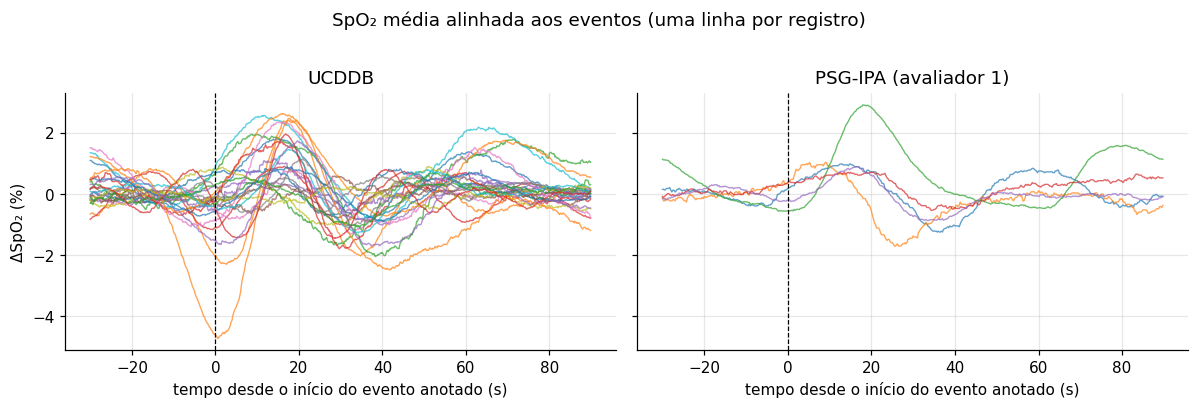

Registros com queda média < 1 % (conferir alinhamento): [('UCDDB', 'ucddb002'), ('UCDDB', 'ucddb008'), ('UCDDB', 'ucddb012'), ('UCDDB', 'ucddb013'), ('UCDDB', 'ucddb014'), ('UCDDB', 'ucddb018'), ('UCDDB', 'ucddb019'), ('UCDDB', 'ucddb021'), ('UCDDB', 'ucddb022'), ('UCDDB', 'ucddb024'), ('PSG-IPA', 'SN3'), ('PSG-IPA', 'SN4'), ('PSG-IPA', 'SN5')]
APNEA HRV+SpO₂ — amplitude mediana da SpO₂ por minuto: com apneia 4.05 %, sem apneia 1.02 % (83 sujeitos)
  sujeitos em que minutos com apneia NÃO variam mais: ['C13', 'C15', 'ND5']


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
quedas = {}
for ax, base in zip(axs, ["ucddb", "psgipa"]):
    for (b, r), c in cache.items():
        if b != base:
            continue
        t, m, n = media_alinhada_eventos(c["x"], c["fs"], c["eventos"])
        if n >= 5:
            ax.plot(t, m, lw=0.9, alpha=.7)
            quedas[(BASES[b]["sigla"], r)] = float(np.nanmin(m))
    ax.axvline(0, color="k", lw=.8, ls="--")
    ax.set(title=BASES[base]["sigla"] + (f" (avaliador {PSGIPA_AVALIADOR_FIGURAS})" if base == "psgipa" else ""),
           xlabel="tempo desde o início do evento anotado (s)")
axs[0].set_ylabel("ΔSpO₂ (%)")
fig.suptitle("SpO₂ média alinhada aos eventos (uma linha por registro)", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR / "checagem_alinhamento.png", dpi=150, bbox_inches="tight"); plt.show()

quedas = pd.Series(quedas, name="queda_media_pct")
print("Registros com queda média < 1 % (conferir alinhamento):", list(quedas[quedas > -1].index) or "nenhum")

amp = [{"registro": r, "apneia": a, "sem_apneia": s}
       for (b, r), c in cache.items() if b == "apnea_hrv_spo2" and c["rotulos_min"] is not None
       for a, s in [variacao_por_minuto(c["xv"], c["fs"], c["rotulos_min"])]]
if amp:
    amp = pd.DataFrame(amp)
    print(f"APNEA HRV+SpO₂ — amplitude mediana da SpO₂ por minuto: com apneia {amp.apneia.median():.2f} %, "
          f"sem apneia {amp.sem_apneia.median():.2f} % ({len(amp)} sujeitos)")
    print("  sujeitos em que minutos com apneia NÃO variam mais:", list(amp[amp.apneia <= amp.sem_apneia].registro) or "nenhum")

## 8. Figuras: sinal bruto × pré-processado

Em cada base é usado o registro mais grave (maior IAH; na APNEA HRV+SpO₂, maior % de minutos com apneia).
* **Figura 1** — noite inteira, bruto (convertido para %) e validado; vigília sombreada quando há hipnograma.
* **Figura 2** — janela de 10 min com mais eventos: bruto × média móvel × wavelet na fs nativa; faixas laranja =
  eventos (UCDDB, PSG-IPA avaliador 1) ou minutos com apneia (APNEA HRV+SpO₂).
* **Figura 3** — a mesma janela nas 5 frequências.
* **Figura 4** — PSG-IPA: SpO₂ com os eventos marcados por cada um dos 12 avaliadores.

Registros das figuras: {'ucddb': 'ucddb025', 'apnea_hrv_spo2': 'D29', 'psgipa': 'SN3'}


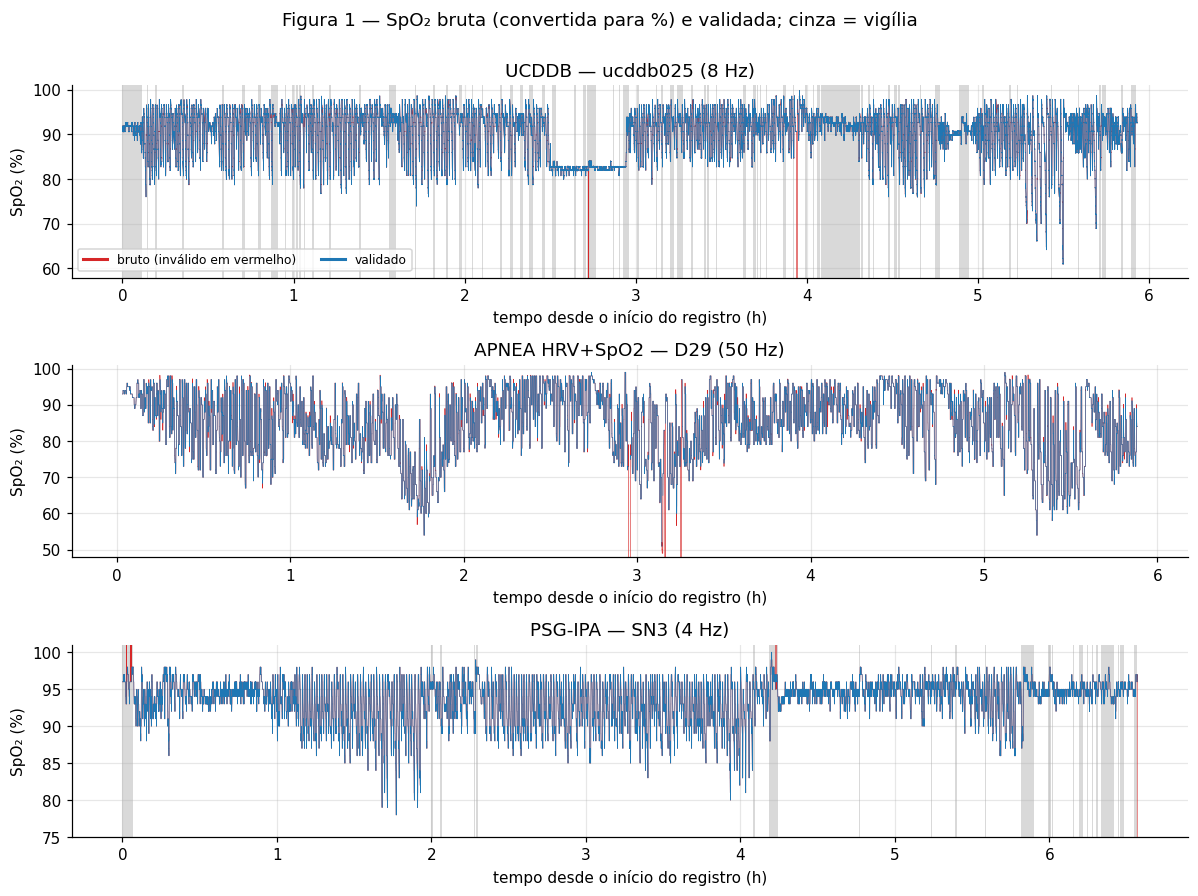

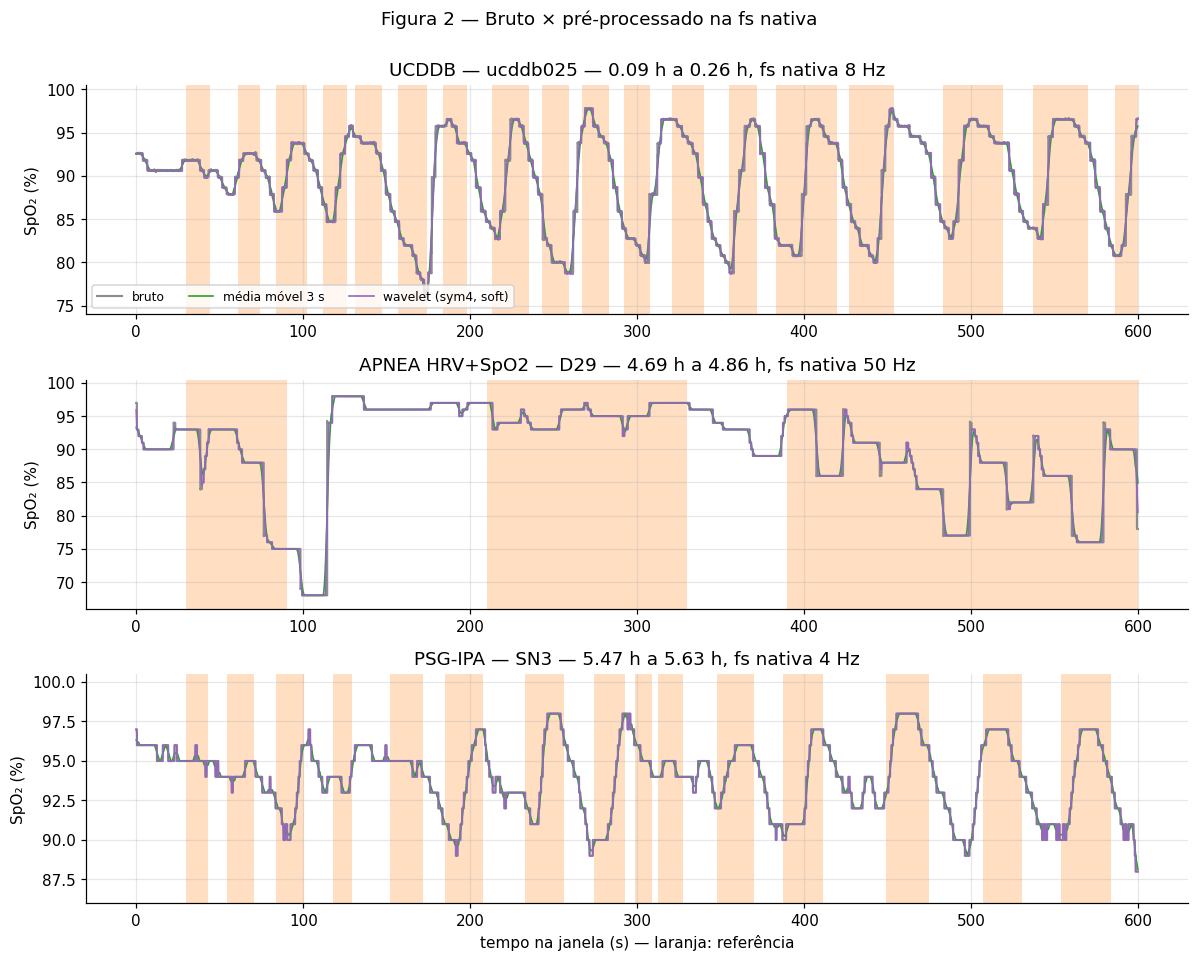

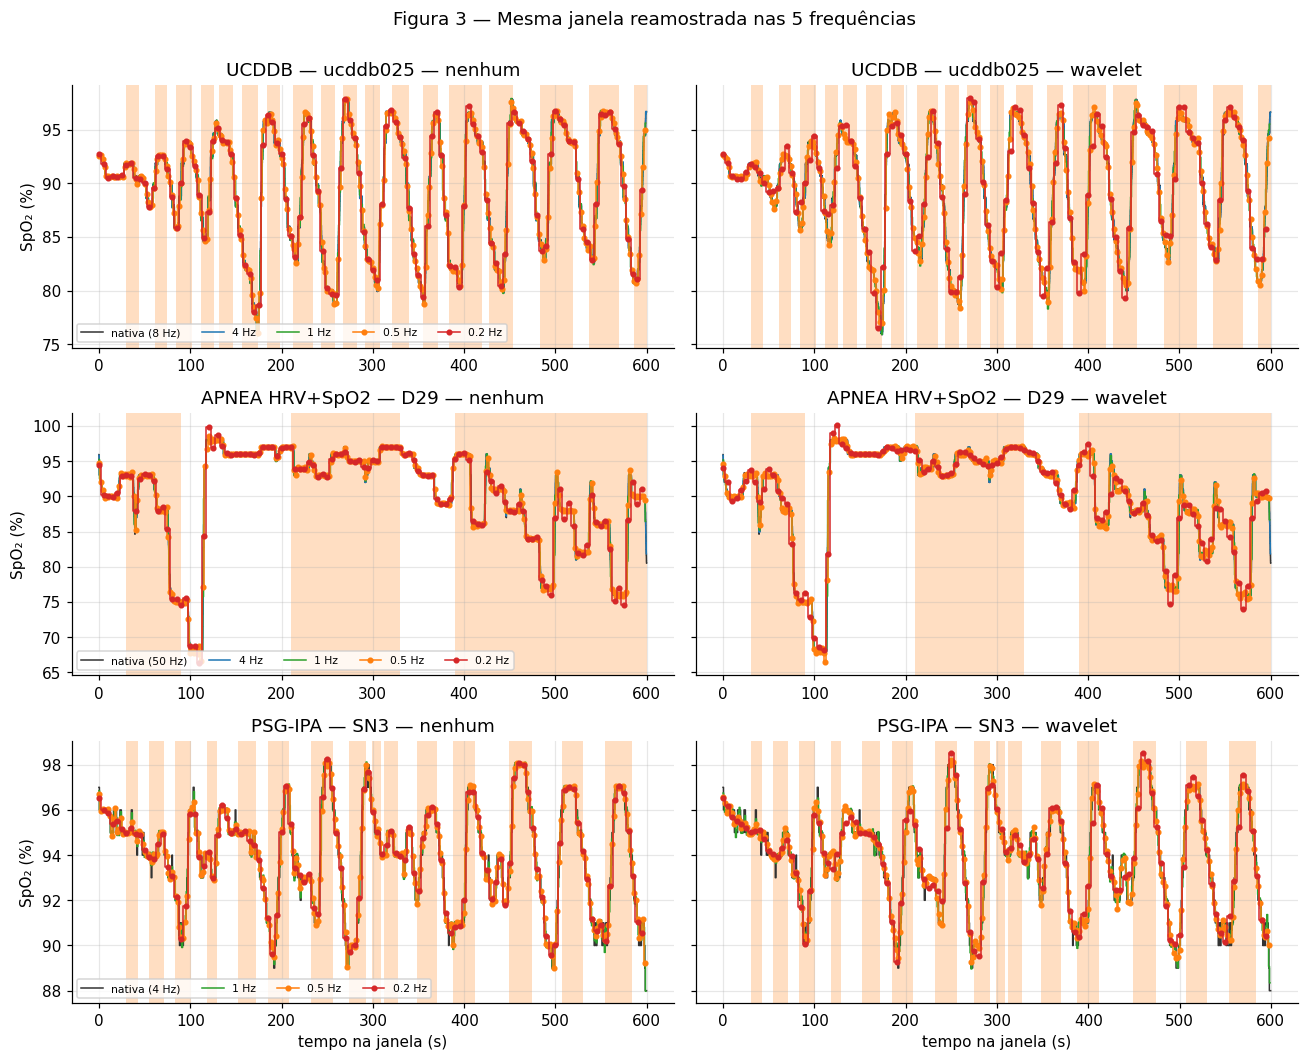

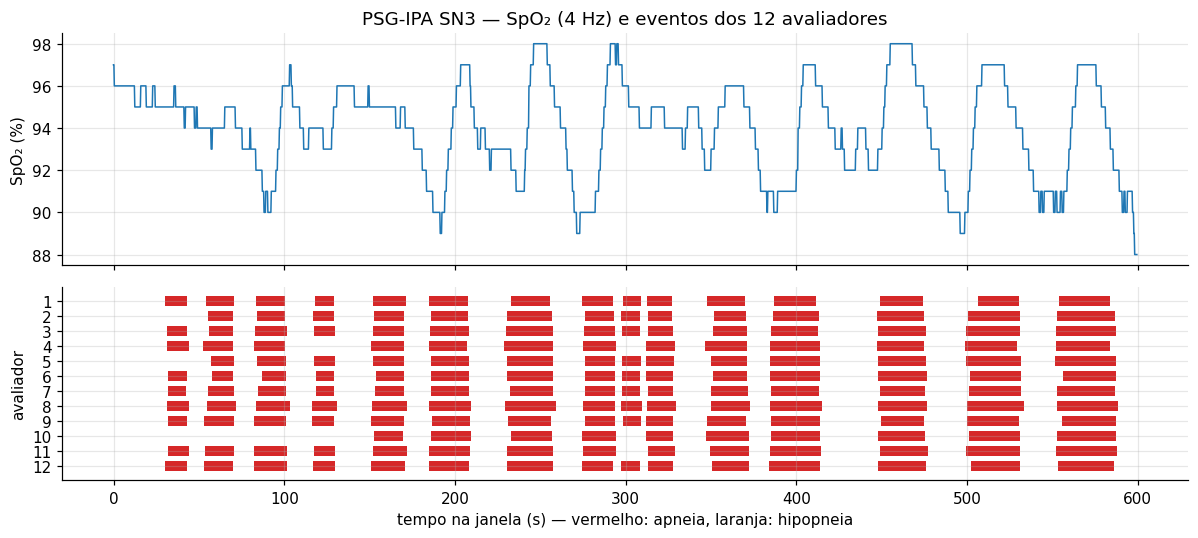

In [16]:
ORDEM = [b for b in ["ucddb", "apnea_hrv_spo2", "psgipa"] if any(k[0] == b for k in cache)]
FIG_REG = {}
for b in ORDEM:
    d = descricao[descricao.base == BASES[b]["sigla"]].dropna(subset=["gravidade"])
    d = d[d["duracao_registro_h"] >= 1]                       # registros com pelo menos 1 h de sinal
    if "rotulos_menos_minutos_sinal" in d and d["rotulos_menos_minutos_sinal"].notna().any():
        d = d[d["rotulos_menos_minutos_sinal"].abs() <= 5]    # rótulos e sinal com a mesma duração
    if len(d):
        FIG_REG[b] = d.sort_values("gravidade").iloc[-1]["registro"]
print("Registros das figuras:", FIG_REG)


def intervalos_referencia(c):
    '''Intervalos (início, fim) em s da referência: eventos (apneia/hipopneia) ou minutos com apneia.'''
    if c["eventos"] is not None:
        e = c["eventos"][c["eventos"]["classe"] != "resp_periodica"]
        return list(zip(e.inicio_s, e.fim_s))
    if c["rotulos_min"] is not None:
        return [(60 * a, 60 * b) for a, b in trechos(np.asarray(c["rotulos_min"], bool))]
    return []


def janela_mais_eventos(c, dur_s=600):
    total = len(c["x"]) / c["fs"]
    ini = np.array([a for a, _ in intervalos_referencia(c)])
    ini = ini[ini <= max(total - dur_s, 0)]
    if len(ini) == 0:
        return 0.0
    cont = [np.sum((ini >= a) & (ini < a + dur_s)) for a in ini]
    return max(0.0, float(ini[int(np.argmax(cont))]) - 30)


def sombrear(ax, c, t0, t1, escala=1.0):
    for a, b in intervalos_referencia(c):
        if b > t0 and a < t1:
            ax.axvspan((max(a, t0) - t0) * escala, (min(b, t1) - t0) * escala, color="tab:orange", alpha=.25, lw=0)


def titulo(b):
    return f"{BASES[b]['sigla']} — {FIG_REG[b]}"


# Figura 1 — noite inteira
fig, axs = plt.subplots(len(FIG_REG), 1, figsize=(11, 2.7 * len(FIG_REG)), squeeze=False)
for ax, b in zip(axs[:, 0], FIG_REG):
    c = cache[(b, FIG_REG[b])]
    t = np.arange(len(c["x"])) / c["fs"] / 3600
    if c["estagios"] is not None:
        for a, e in trechos(np.asarray(c["estagios"]) == 0):
            ax.axvspan(a * EPOCA_S / 3600, e * EPOCA_S / 3600, color="0.85", lw=0, zorder=0)
    ax.plot(t, np.clip(c["x"], 0, 101), color="tab:red", lw=.4, label="bruto (inválido em vermelho)")
    ax.plot(t, c["xv"], color="tab:blue", lw=.4, label="validado")
    ax.set(ylim=(max(40, np.nanmin(c["xv"]) - 3), 101), ylabel="SpO₂ (%)",
           title=f"{titulo(b)} ({c['fs']:g} Hz)", xlabel="tempo desde o início do registro (h)")
for l in axs[0, 0].legend(loc="lower left", fontsize=8, ncol=2).get_lines():
    l.set_linewidth(2)
fig.suptitle("Figura 1 — SpO₂ bruta (convertida para %) e validada; cinza = vigília", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_noite_bruto_validado.png", dpi=150, bbox_inches="tight"); plt.show()

# Figura 2 — zoom de 10 min, bruto × pré-processamentos na fs nativa
janelas = {}
fig, axs = plt.subplots(len(FIG_REG), 1, figsize=(11, 2.9 * len(FIG_REG)), squeeze=False)
for ax, b in zip(axs[:, 0], FIG_REG):
    c = cache[(b, FIG_REG[b])]; fs = c["fs"]
    t0 = janela_mais_eventos(c); t1 = min(t0 + 600, len(c["x"]) / fs); janelas[b] = (t0, t1)
    i0, i1 = int(t0 * fs), min(int(t1 * fs), len(c["x"]))
    tt = np.arange(i1 - i0) / fs
    xv = c["xv"][i0:i1].astype(float)
    v = preprocessar_registro(xv, fs)
    sombrear(ax, c, t0, t1)
    ax.plot(tt, c["x"][i0:i1], color="0.55", lw=1.4, label="bruto", drawstyle="steps-mid")
    ax.plot(tt, v[("nativa", "media_movel")][0], color="tab:green", lw=1.1, label="média móvel 3 s")
    if v[("nativa", "wavelet")][0] is not None:
        ax.plot(tt, v[("nativa", "wavelet")][0], color="tab:purple", lw=1.1, label="wavelet (sym4, soft)")
    inval = np.isnan(xv)
    vmin = np.nanmin(xv) if (~inval).any() else 80
    if inval.any():
        ax.plot(tt[inval], np.full(inval.sum(), vmin - 1), "|", color="tab:red", ms=6, label="lacuna longa (excluída)")
    ax.set(ylim=(vmin - 2, 100.5), ylabel="SpO₂ (%)",
           title=f"{titulo(b)} — {t0 / 3600:.2f} h a {t1 / 3600:.2f} h, fs nativa {fs:g} Hz")
axs[0, 0].legend(loc="lower left", fontsize=8, ncol=4)
axs[-1, 0].set_xlabel("tempo na janela (s) — laranja: referência")
fig.suptitle("Figura 2 — Bruto × pré-processado na fs nativa", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_zoom_preprocessamento.png", dpi=150, bbox_inches="tight"); plt.show()

# Figura 3 — a mesma janela nas 5 frequências (sem filtro × wavelet)
cores = dict(zip(FS_ALVO, ["0.2", "tab:blue", "tab:green", "tab:orange", "tab:red"]))
met2 = "wavelet" if pywt is not None else "media_movel"
fig, axs = plt.subplots(len(FIG_REG), 2, figsize=(12, 3.2 * len(FIG_REG)), squeeze=False, sharey="row")
for linha, b in zip(axs, FIG_REG):
    c = cache[(b, FIG_REG[b])]; fs = c["fs"]
    t0, t1 = janelas[b]
    v = preprocessar_registro(c["xv"][int(t0 * fs):int(t1 * fs)].astype(float), fs)
    for ax, met in zip(linha, ["nenhum", met2]):
        sombrear(ax, c, t0, t1)
        for alvo in FS_ALVO:
            z, fz = v[(alvo, met)]
            if z is None or (alvo != "nativa" and np.isclose(fz, fs)):
                continue
            ax.plot(np.arange(len(z)) / fz, z, color=cores[alvo], lw=1, drawstyle="steps-mid",
                    marker="o" if fz <= 0.5 else None, ms=3,
                    label=(f"nativa ({fz:g} Hz)" if alvo == "nativa" else f"{alvo:g} Hz"))
        ax.set(title=f"{titulo(b)} — {met}")
    linha[0].set_ylabel("SpO₂ (%)")
    linha[0].legend(fontsize=7, ncol=5, loc="lower left")
for ax in axs[-1]:
    ax.set_xlabel("tempo na janela (s)")
fig.suptitle("Figura 3 — Mesma janela reamostrada nas 5 frequências", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_frequencias.png", dpi=150, bbox_inches="tight"); plt.show()

# Figura 4 — PSG-IPA: eventos de cada avaliador
if "psgipa" in FIG_REG:
    c = cache[("psgipa", FIG_REG["psgipa"])]; fs = c["fs"]
    t0, t1 = janelas["psgipa"]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
    a1.plot(np.arange(int(t0 * fs), int(t1 * fs)) / fs - t0, c["xv"][int(t0 * fs):int(t1 * fs)], color="tab:blue", lw=1)
    a1.set(ylabel="SpO₂ (%)", title=f"PSG-IPA {FIG_REG['psgipa']} — SpO₂ (4 Hz) e eventos dos 12 avaliadores")
    for k, ev in c["eventos_avaliadores"].items():
        sel = ev[(ev.fim_s > t0) & (ev.inicio_s < t1)]
        for _, e in sel.iterrows():
            a2.barh(k, e.fim_s - e.inicio_s, left=e.inicio_s - t0, height=.7,
                    color="tab:red" if e.classe == "apneia" else "tab:orange")
    a2.set(yticks=PSGIPA_AVALIADORES, ylabel="avaliador", xlabel="tempo na janela (s) — vermelho: apneia, laranja: hipopneia")
    a2.invert_yaxis()
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_psgipa_avaliadores.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Números que motivam as dúvidas sobre o detector (Etapa 4)

In [17]:
ucd = [c["eventos"].assign(registro=r) for (b, r), c in cache.items() if b == "ucddb"]
if ucd:
    resp = pd.concat(ucd)
    resp = resp[resp.classe != "resp_periodica"]
    cq = resp.queda_pct.notna()
    print(f"UCDDB — eventos: {len(resp)}; com queda anotada: {cq.mean():.0%}; "
          f"queda ≥ 3 %: {(resp.queda_pct[cq] >= 3).mean():.0%}; ≥ 4 %: {(resp.queda_pct[cq] >= 4).mean():.0%}; "
          f"hipopneias com queda < 3 %: {((resp.classe == 'hipopneia') & (resp.queda_pct < 3)).sum()}")
    gaps = resp.sort_values(["registro", "inicio_s"]).groupby("registro")["inicio_s"].diff()
    print(f"UCDDB — eventos que começam < 30 s após o anterior: {(gaps < 30).mean():.0%}")
if len(contagens_psgipa):
    g = contagens_psgipa.groupby("registro")["IAH"]
    print("PSG-IPA — IAH entre avaliadores (mín–máx):", {r: f"{a:.1f}–{b:.1f}" for r, a, b in zip(g.min().index, g.min(), g.max())})
d = descricao[descricao.base == "APNEA HRV+SpO2"]
if len(d):
    print(f"APNEA HRV+SpO₂ — rótulos − minutos de sinal: {faixa(d['rotulos_menos_minutos_sinal'], '{:.1f}')} min; "
          f"grupos: {d['grupo'].value_counts(dropna=False).to_dict()}")
print("Passo de quantização observado (%):", metadados.groupby("base")["passo_observado"].unique().to_dict())
print("Amostras em 10 s por fs:", {str(a): (10 * a if a != "nativa" else "10·fs nativa") for a in FS_ALVO})
print("Janela da média móvel de 3 s (amostras):", {str(a): max(1, round(3 * a)) for a in FS_ALVO if a != "nativa"})
print("Nível wavelet por fs:", {f"{f:g} Hz": nivel_wavelet(f) for f in [50, 8, 4, 1, 0.5, 0.2]})

UCDDB — eventos: 3318; com queda anotada: 95%; queda ≥ 3 %: 84%; ≥ 4 %: 71%; hipopneias com queda < 3 %: 436
UCDDB — eventos que começam < 30 s após o anterior: 19%
PSG-IPA — IAH entre avaliadores (mín–máx): {'SN1': '4.7–6.6', 'SN2': '1.6–6.8', 'SN3': '45.1–56.0', 'SN4': '0.2–6.3', 'SN5': '3.6–14.4'}
APNEA HRV+SpO₂ — rótulos − minutos de sinal: 0.0–212.0 min; grupos: {'controle': 38, 'dessaturante': 34, 'não dessaturante': 11}
Passo de quantização observado (%): {'APNEA HRV+SpO2': array([0.009155]), 'PSG-IPA': array([1.]), 'UCDDB': array([0.023687])}
Amostras em 10 s por fs: {'nativa': '10·fs nativa', '4.0': 40.0, '1.0': 10.0, '0.5': 5.0, '0.2': 2.0}
Janela da média móvel de 3 s (amostras): {'4.0': 12, '1.0': 3, '0.5': 2, '0.2': 1}
Nível wavelet por fs: {'50 Hz': 6, '8 Hz': 4, '4 Hz': 3, '1 Hz': 1, '0.5 Hz': 1, '0.2 Hz': 1}


### Dúvidas concretas sobre o algoritmo principal e seus parâmetros

**Detector (linha de base e critério de dessaturação)**
1. **Linha de base = mediana dos 120 s anteriores.** A janela deve excluir amostras que já fazem parte de uma
   dessaturação detectada e as lacunas `NaN`? Com eventos a cada ~40 s, a mediana de 120 s sem exclusão fica
   rebaixada e o detector perde eventos.
2. **"Pelo menos 3 %"** com SpO₂ quantizada (passo impresso acima): `≥ 3` e `> 3` dão resultados diferentes. Qual
   comparação usar, e o limiar vale antes ou depois do pré-processamento (que cria valores intermediários)?
3. **Duração mínima de 10 s**: contar `ceil(10·fs)` amostras abaixo do limiar? A 0,2 Hz são 2 amostras. Aceitamos
   tolerância de 1 amostra acima do limiar dentro do evento?
4. **Eventos próximos**: dessaturações separadas por menos de X s devem ser fundidas? Uma dessaturação longa que cobre
   duas apneias anotadas conta como um ou dois acertos?

**Avaliação**
5. **Pareamento 1 a 1** na janela [início, fim + 30 s]: pretendemos usar pareamento guloso por proximidade — adequado?
6. **Hipopneias sem dessaturação** (UCDDB): parte tem queda anotada < 3 %, invisível para um detector de SpO₂. Relatar
   a sensibilidade também estratificada pela queda anotada?
7. **IAH de referência da UCDDB**: o do `SubjectDetails.xls` ou o recalculado pelas anotações e pelo tempo de sono?
8. **Eventos PB/CS** (UCDDB) entram na referência?
9. **Denominador do ODI**: horas de sono válido (sem vigília, épocas 6/7 e lacunas > 10 s), como implementado?

**Bases externas**
10. **APNEA HRV+SpO₂ — rótulos por minuto**: como converter as detecções? Proposta: minuto positivo se contém o
    *nadir* de uma dessaturação detectada. Como a queda da SpO₂ atrasa ~30 s, aceitar também o minuto seguinte ao
    rotulado?
11. **APNEA HRV+SpO₂ sem hipnograma**: o ODI fica por hora de registro, e não por hora de sono, nesta base. Isso
    impede comparar o valor absoluto do ODI com as outras bases — basta comparar sensibilidade/especificidade por
    minuto?
12. **APNEA HRV+SpO₂ — grupo "não dessaturante"** (11 sujeitos com IAH alto e pouca dessaturação): relatar em separado,
    já que um detector só de SpO₂ deve falhar neles por construção?
13. **PSG-IPA — referência com 12 avaliadores**: comparar o detector com cada avaliador e confrontar com a
    concordância entre pares de avaliadores (como na Entrega 1), ou também com um consenso (evento marcado por ≥ 7
    de 12)? Usamos só o modo manual — o semiautomático fica de fora?
14. **PSG-IPA a 4 Hz nativos**: "nativa" e "4 Hz" coincidem; a comparação de frequências nesta base fica com 4 níveis.
    Tudo bem?

**Pré-processamento (fatores em teste)**
15. **Média móvel de 3 s em fs baixa**: a 0,5 Hz vira 2 amostras e a 0,2 Hz vira 1 (sem efeito). Janela fixa em
    segundos (e relatar o efeito nulo) ou número mínimo de amostras?
16. **Wavelet**: `sym4`, limiar universal, *soft*, nível pela escala de ~2 s (nível 1 em fs ≤ 1 Hz) — aceitável, ou
    fixar o mesmo nível em todas as fs?
17. **Regra de salto (4 %/s)**: com o mesmo valor nas três bases (fs de 4 a 50 Hz) ela age de forma diferente; mantemos
    os parâmetros congelados mesmo assim (regra da Etapa 6)?

## 10. Resumo para o relatório

In [18]:
reg = json.loads((SAIDA_DIR / "registro_acesso.json").read_text())
resumo = {}
for b in BASES:
    m = metadados[metadados.base == BASES[b]["sigla"]]
    dsc = descricao[descricao.base == BASES[b]["sigla"]]
    resumo[b] = {"base": BASES[b]["nome"], "papel": BASES[b]["papel"], "versao": BASES[b]["versao"],
                 "doi": BASES[b]["doi"], "licenca": BASES[b]["licenca"],
                 "data_acesso": reg.get(b, {}).get("data_acesso"),
                 "registros": int(len(dsc)), "fs_spo2_hz": sorted(map(float, m["fs_hz"].unique())),
                 "unidade": sorted(map(str, m["unidade"].unique())),
                 "ganho_por_LSB": sorted(m["ganho_por_LSB"].dropna().round(6).unique().tolist()),
                 "passo_observado_pct": sorted(m["passo_observado"].dropna().round(4).unique().tolist()),
                 "horas_gravadas": round(float(dsc["duracao_registro_h"].sum()), 1),
                 "horas_validas_analise": round(float(dsc["analise_valida_h"].sum()), 1),
                 "falha": falhas.get(b)}
(SAIDA_DIR / "resumo_entrega2.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False, default=str))
print(json.dumps(resumo, indent=2, ensure_ascii=False, default=str))
print("\nArquivos gerados:")
for p in sorted(SAIDA_DIR.rglob("*")):
    if p.is_file() and "preprocessado" not in p.parts:
        print(" ", p)

{
  "ucddb": {
    "base": "St. Vincent's University Hospital / University College Dublin Sleep Apnea Database (UCDDB)",
    "papel": "principal",
    "versao": "1.0.0",
    "doi": "10.13026/C26C7D",
    "licenca": "ODC-By v1.0",
    "data_acesso": "2026-11-11T18:59:48-03:00",
    "registros": 25,
    "fs_spo2_hz": [
      8.0
    ],
    "unidade": [
      "%"
    ],
    "ganho_por_LSB": [
      0.023687
    ],
    "passo_observado_pct": [
      0.0237
    ],
    "horas_gravadas": 173.4,
    "horas_validas_analise": 133.1,
    "falha": null
  },
  "apnea_hrv_spo2": {
    "base": "APNEA HRV+SpO2 Dataset (base HuGCDN2014-OXI, Hosp. Univ. Dr. Negrín)",
    "papel": "externa 1",
    "versao": "1",
    "doi": "10.17632/cdxs63gdzc.1",
    "licenca": "CC BY 4.0",
    "data_acesso": "2026-11-11T18:59:48-03:00",
    "registros": 83,
    "fs_spo2_hz": [
      50.0
    ],
    "unidade": [
      "% (assumida; não informada)"
    ],
    "ganho_por_LSB": [],
    "passo_observado_pct": [
      0.0092

## 11. Baixar as saídas para o repositório

Gera `saidas_entrega2.zip` com as tabelas, o registro de acesso e as figuras (sem os sinais pré-processados, que são
grandes e podem ser recriados pelo notebook). No Colab o download começa sozinho; com o Drive ativo, o arquivo
também fica em `egc_apneia/` no seu Drive.

In [19]:
destino_zip = RAIZ / "saidas_entrega2.zip"
with zipfile.ZipFile(destino_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(SAIDA_DIR.rglob("*")):
        if p.is_file() and "preprocessado" not in p.parts:
            zf.write(p, p.relative_to(SAIDA_DIR.parent))
print(f"{destino_zip}: {destino_zip.stat().st_size / 1e6:.1f} MB")
try:
    from google.colab import files
    files.download(str(destino_zip))
except ImportError:
    pass

/content/drive/MyDrive/egc_apneia/saidas_entrega2.zip: 1.5 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>